In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

# Imports

In [3]:
# %pip install numpy pandas scipy xarray netCDF4 matplotlib cartopy

from pathlib import Path
import hashlib
import json
import os
import time
import uuid
import calendar
import re

import numpy as np
import pandas as pd
import xarray as xr
from scipy.spatial import cKDTree
from scipy.stats import rankdata

VERSION = "seasonal-1.0"
EARTH_KM = 6371.0088
BANDS = ["low", "moderate", "high"]
CORE = ["air_temperature_mean", "snowfall_mean", "relative_humidity_mean", "wind_speed_mean"]
LABELS = {
    "air_temperature_mean": "Air temperature", "snowfall_mean": "Season snowfall total",
    "relative_humidity_mean": "Relative humidity", "wind_speed_mean": "Wind speed",
    "air_temperature_hourly_sd": "Hourly temperature SD",
    "relative_humidity_hourly_sd": "Hourly RH SD",
    "wind_speed_hourly_sd": "Hourly wind SD", "wind_speed_p90": "Mean cell wind p90",
    "snowfall_season_total_sd": "Interannual snowfall-total SD",
    "non_snow_precipitation_mean": "Season non-snow precipitation total",
    "non_snow_precipitation_season_total_sd": "Interannual non-snow-total SD",
}



from IPython.display import display, Image, FileLink

print("Notebook working directory:", Path.cwd())


Notebook working directory: /home/s1803229/Chapter_2/notebooks


# Settings

In [5]:
SOURCE_NC = Path("../../scratch/climate_site_selection/seasonal_climate.nc")
SEASON = "OND"                         # One source label: OND, DJF, FMA, or a custom month range.
PREPARED_DIR = Path("../../scratch/climate_site_selection/seasonal_climatologies")
OUTPUT_DIR = Path("../../scratch/climate_site_selection/regional_site_selection_seasonal")

WIDTH_KM = 400                         # Width along the central latitude of a box.
HEIGHT_KM = 400                        # North–south height.
CANDIDATE_SPACING_KM = 100             # Try 50 km for a finer search or 200 km boxes.
MIN_CANOPY_COVERAGE = 0.50             # at least x% of pixels have a valid canopy cover value
MIN_CANOPY_COVER = 10.0                # Minimum average tree canopy cover within a grid cell (%).
MIN_TEMPORAL_COVERAGE = 0.50           # Pooled valid hours / expected hours; complete-year fraction for snow.
MIN_USABLE_FRACTION = 0.50             # Eligible area / entire box area.
MIN_CELL_SNOWFALL = None               # Optional minimum; same units as snowfall_mean.

SELECTION_VARIABLES = [
    "air_temperature_mean",
    "snowfall_mean",
    "relative_humidity_mean",
    "wind_speed_mean",
]
DIAGNOSTIC_VARIABLES = [
    "air_temperature_hourly_sd", "relative_humidity_hourly_sd", "wind_speed_hourly_sd",
    "wind_speed_p90", "snowfall_season_total_sd",
    "non_snow_precipitation_mean", "non_snow_precipitation_season_total_sd",
]
MAX_SPATIAL_SD = {}                    # Optional limits, e.g. {"air_temperature_mean": 3.0}.

SAMPLE_SIZES = list(range(5, 10))       # Evaluate 5 through 9 sites, as in the attached notebook.

CLIMATE_COVERAGE_TOLERANCE = 0.25      # A candidate is represented when a selected site's
                                      # quantile differs by <=x in every climate variable.
TARGET_CLIMATE_COVERAGE = 0.85        # Diagnostic target; the minimum objective determines the recommendation.
MIN_COVERAGE_GAIN = 0.05              # Flag improvements below x percentage point; not a stopping rule.

RANDOM_SEED = 1729
RESTARTS = 4                           # Independent optimisation attempts per size.
ITERATIONS = 20000                     # Proposals per optimisation attempt.
MAX_OVERLAP_FRACTION = 0.00             # fraction of two selected boxes that are allowed to overlap
MIN_BAND_FRACTION = 0.35                # Useful canopy band: fraction of eligible area.
CLIMATE_MATCH_TOLERANCE = CLIMATE_COVERAGE_TOLERANCE # Maximum difference in each climate's quantile to be considered canopy cover pairs
                                        # i.e. two regions to have similar climate, but one has low and the other has high canopy cover

INITIAL_TEMPERATURE = 0.03             # Simulated-annealing controls.
FINAL_TEMPERATURE = 0.0001
COMPLEMENT_PROPOSAL_FRACTION = 0.25    # this specifies how often the cLHS looks for a canopy cover pair for an existing candidate
OBJECTIVE_WEIGHTS = {
    "climate_gap": 1.0,        # Penalise the fraction of candidates not climatically represented.
    "marginal": 1.0,            # sampling across the range of each climate variable, primary goal
    "correlation": 0.2,         # retaining the relationships between climate variables found in candidate population
    "canopy_gap": 0.35,         # selecting canopy contrasts wherever suitable candidates exist
    "climate_spread": 0.05,     # choosing regions with less internal climate variation
}
FIGURE_DPI = 170

# Shared Functions

In [6]:
def log(message):
    # Show progress immediately, with the current time.
    print(time.strftime("[%H:%M:%S] ") + str(message), flush=True)


def digest(value):
    # Give a combination of settings a repeatable experiment ID.
    # Later code uses this ID in the results-folder name.
    text = json.dumps(value, sort_keys=True, allow_nan=False)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]


def atomic_json(path, value):
    # Save a small record: settings, completed variables, or finished experiments.
    # Later code reads these records to decide what can be reused or skipped.
    path = Path(path)
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")

    try:
        temp.write_text(
            json.dumps(value, indent=2, allow_nan=False),
            encoding="utf-8",
        )  # Write to a temporary file first.
        os.replace(temp, path)  # Replace the final file only when writing succeeds.
    finally:
        temp.unlink(missing_ok=True)  # Remove any leftover temporary file.


def atomic_csv(path, table):
    # Save actual tables, including candidate summaries and selected sites.
    # The temporary-file approach protects an existing table from a partial write.
    path = Path(path)
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")

    try:
        table.to_csv(temp, index=False)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def source_signature(path):
    # Record which input NetCDF this experiment uses.
    # Include this information in the experiment ID so an updated NetCDF
    # does not accidentally reuse results calculated from an older file.
    p = Path(path).expanduser().resolve()
    s = p.stat()

    return {
        "path": str(p),           # Full input-file location.
        "bytes": s.st_size,       # File size.
        "mtime_ns": s.st_mtime_ns,  # Last modification time.
    }  # This checks file metadata, without reading the whole NetCDF.


def edges(centres):
    # Convert cell-centre coordinates into cell boundaries.
    # Example: centres [10, 11, 12] → edges [9.5, 10.5, 11.5, 12.5].
    # We need boundaries to calculate areas and align study boxes to whole cells.
    centres = np.asarray(centres, dtype=np.float64)

    if centres.ndim != 1 or centres.size < 2:
        raise ValueError("Expected a 1D coordinate array with at least two centres")

    d = np.diff(centres)  # Spacing between neighbouring cell centres.

    if (
        not np.all(np.isfinite(centres))
        or not np.all(d > 0)
        or not np.allclose(d, np.median(d), rtol=1e-4, atol=1e-6)
    ):
        raise ValueError(
            "Expected regular, increasing, unique latitude and longitude coordinates"
        )

    return np.r_[
        centres[0] - d[0] / 2,           # Outer boundary before the first centre.
        (centres[:-1] + centres[1:]) / 2,  # Boundaries between neighbouring centres.
        centres[-1] + d[-1] / 2,         # Outer boundary after the last centre.
    ]


def open_grid(path):
    # Open the NetCDF and arrange its grid consistently for later calculations.
    ds = xr.open_dataset(path)

    try:
        for name in ["latitude", "longitude"]:
            if ds[name].dims != (name,):
                raise ValueError(f"Expected 1D {name} coordinates")

        ds = ds.assign_coords(
            longitude=(ds.longitude + 180) % 360 - 180
        )  # Express longitude as −180 to 180 rather than 0 to 360.

        ds = ds.sortby("latitude").sortby("longitude")
        # Data now run south → north and west → east.

        edges(ds.latitude.values)
        edges(ds.longitude.values)
        # Check that both coordinates have regular spacing.

        return ds  # Return the open dataset for the caller to use and close.

    except Exception:
        ds.close()  # Close the file if preparation fails.
        raise


def map_values(ds, name):
    # Load one variable as a numerical map, with rows = latitude, columns = longitude.
    a = ds[name]

    if set(a.dims) != {"latitude", "longitude"}:
        raise ValueError(
            f"{name} has dimensions {a.dims}; "
            "use the collapsed 2D climatology NetCDF"
        )

    return (
        a.transpose("latitude", "longitude")
        .values.astype(np.float64)
    )  # Load this map into memory, using precision suited to the calculations.


def read_domain(ds, cfg):
    # Create a True/False map identifying cells that satisfy all eligibility rules.
    cc = map_values(ds, "tree_canopy_cover_2020")
    cov = map_values(ds, "tree_canopy_coverage_fraction")

    valid = (
        np.isfinite(cc)
        & (cc >= cfg["min_canopy_cover"])  # At least 10% canopy with your settings.
        & (cc <= 100)
    )

    valid &= (
        np.isfinite(cov)
        & (cov >= cfg["min_canopy_coverage"])  # Enough valid canopy-map coverage.
        & (cov <= 1.001)  # Small allowance for numerical rounding around 1.
    )  # Each &= adds another requirement; rejected cells remain rejected.

    for name in CORE:
        a = map_values(ds, name)
        valid &= np.isfinite(a)  # Require valid temperature, snowfall, RH and wind.

        if name in ["snowfall_mean", "wind_speed_mean"]:
            valid &= a >= 0

        if name == "relative_humidity_mean":
            valid &= (a >= 0) & (a <= 100)

        if cfg["min_temporal_coverage"] is not None:
            coverage_name = name + "_valid_fraction"

            if coverage_name not in ds:
                raise ValueError(
                    f"Missing {coverage_name}; use the prepared seasonal NetCDF "
                    "or set MIN_TEMPORAL_COVERAGE = None to disable this check"
                )

            frac = map_values(ds, coverage_name)
            valid &= (
                np.isfinite(frac)
                & (frac >= cfg["min_temporal_coverage"])
            )  # Enough pooled valid hours or complete precipitation season-years.

    for name in cfg["selection_variables"]:
        if name not in CORE:
            valid &= np.isfinite(map_values(ds, name))
            # Require valid values for any additional selection variables.

    if cfg["min_cell_snowfall"] is not None:
        valid &= (
            map_values(ds, "snowfall_mean")
            >= cfg["min_cell_snowfall"]
        )  # Apply a snowfall minimum only if you specify one.

    if not valid.any():
        raise ValueError(
            "No eligible cells remain; inspect data coverage and thresholds"
        )

    return cc, valid  # Return canopy cover and the eligibility mask.


def rect_area(w, s, e, n):
    # Calculate a latitude/longitude rectangle's area in km².
    # Used for cell-area weights, study-box areas and box overlap.
    return (
        EARTH_KM**2
        * np.deg2rad(np.asarray(e) - np.asarray(w))
        * (
            np.sin(np.deg2rad(n))
            - np.sin(np.deg2rad(s))
        )
    )  # Account for longitude lines converging toward the poles.


def integral(a):
    # Prepare cumulative sums once, so thousands of boxes can be summarised quickly.
    out = np.zeros(
        (a.shape[0] + 1, a.shape[1] + 1),
        dtype=np.float64,
    )  # The extra zero row and column make edge calculations straightforward.

    out[1:, 1:] = np.cumsum(
        np.cumsum(a, axis=0),
        axis=1,
    )

    return out


def rect_sum(table, r0, r1, c0, c1):
    # Retrieve a box's sum from the cumulative table using only four entries.
    # Equivalent to summing the original array over [r0:r1, c0:c1].
    return (
        table[r1, c1]
        - table[r0, c1]
        - table[r1, c0]
        + table[r0, c0]
    )

# Prepare the selected period

In [7]:
def season_dates(label, year):
    # Match the winter-year convention in the supplied creation script.
    named = {"OND": (10, 12), "DJF": (12, 2), "FMA": (2, 4)}
    if label in named:
        start, end = named[label]
    else:
        lookup = {calendar.month_abbr[m].upper(): m for m in range(1, 13)}
        try:
            first, last = label.split("_")
            start, end = lookup[first], lookup[last]
        except (ValueError, KeyError):
            raise ValueError(f"Unrecognised source season label: {label}") from None
    end_year = year - (end >= 10)
    yy, mm = end_year - (start > end), start
    months = []
    while (yy, mm) <= (end_year, end):
        months.append((yy, mm))
        yy, mm = yy + (mm == 12), mm % 12 + 1
    return months


def prepare_season(source, season, folder):
    # Export a 2D view and truthful coverage fields; preserve all source variables.
    source, folder = Path(source), Path(folder)
    season = str(season).upper()
    signature = {"adapter": VERSION, "source": source_signature(source), "season": season}
    folder.mkdir(parents=True, exist_ok=True)
    output = folder / f"seasonal_climatology_{season}.nc"
    record = output.with_suffix(".json")
    if output.exists() and record.exists():
        if json.loads(record.read_text()) == signature:
            log(f"Reusing prepared {season} climatology: {output}")
            return output

    with xr.open_dataset(source) as original:
        available = original.season.values.astype(str).tolist()
        if season not in available:
            raise ValueError(f"SEASON={season!r}; available seasons: {available}")
        match = re.fullmatch(r"(\d{4})-(\d{4})", str(original.attrs.get("season_years", "")))
        if match is None:
            raise ValueError("Source must include season_years, e.g. '2019-2021'")
        first, last = map(int, match.groups())
        years = list(range(first, last + 1))
        if not years:
            raise ValueError("Source season_years is empty")
        expected_days = [sum(calendar.monthrange(y, m)[1] for y, m in season_dates(season, winter))
                         for winter in years]
        expected_hours = 24 * sum(expected_days)
        ds = original.sel(season=season, drop=True)
        # +180 and -180 denote the same meridian; retain the -180 source cell.
        raw_lon = ds.longitude.values.astype(float)
        lon = np.round((raw_lon + 180) % 360 - 180, 8)
        order = np.argsort(raw_lon, kind="stable")
        _, indices = np.unique(lon[order], return_index=True)
        keep = order[indices]
        ds = ds.isel(longitude=keep).assign_coords(longitude=lon[keep])
        ds = ds.sortby("latitude").sortby("longitude")
        ds = ds.rename({
            "temperature_mean": "air_temperature_mean",
            "temperature_sd": "air_temperature_hourly_sd",
            "relative_humidity_sd": "relative_humidity_hourly_sd",
            "wind_speed_sd": "wind_speed_hourly_sd",
            "snowfall_sd": "snowfall_season_total_sd",
            "non_snow_precipitation_sd": "non_snow_precipitation_season_total_sd",
        })
        hourly_fraction = ds.valid_hour_count.astype("float64") / expected_hours
        for name in ["air_temperature_mean", "relative_humidity_mean", "wind_speed_mean"]:
            ds[name + "_valid_fraction"] = hourly_fraction.astype("float32")
            ds[name + "_valid_fraction"].attrs = {
                "units": "1", "long_name": "Pooled valid-hour fraction across source season-years",
                "description": "Not a per-year minimum; all three hourly metrics share a validity mask",
            }
        for name, count in [("snowfall", "complete_snowfall_seasons"),
                            ("non_snow_precipitation", "complete_non_snow_precipitation_seasons")]:
            ds[name + "_mean_valid_fraction"] = (ds[count] / len(years)).astype("float32")
            ds[name + "_mean_valid_fraction"].attrs = {
                "units": "1", "long_name": "Fraction of source season-years with complete daily totals",
            }
        ds.attrs.update(
            selected_season=season, expected_hour_count=expected_hours,
            expected_days_by_season_year=json.dumps(dict(zip(years, expected_days))),
            preparation_signature=json.dumps(signature, sort_keys=True),
            preparation="Select one already-aggregated season; retain -180 instead of duplicate +180; sort grid",
            temporal_coverage_definition="Pooled valid-hour fraction; precipitation complete-season-year fraction",
            variability_caveat="Hourly SD and interannual precipitation-total SD; daily SD unavailable",
        )
        ds.latitude.attrs.update(units="degrees_north", standard_name="latitude")
        ds.longitude.attrs.update(units="degrees_east", standard_name="longitude")
        temp = output.with_name(output.stem + "." + uuid.uuid4().hex + ".partial.nc")
        try:
            encoding = {name: {"zlib": True, "complevel": 4} for name in ds.data_vars}
            ds.to_netcdf(temp, engine="netcdf4", encoding=encoding)
            os.replace(temp, output)
        finally:
            temp.unlink(missing_ok=True)
    atomic_json(record, signature)
    log(f"Prepared {season}, source season-years {first}–{last}: {output}")
    return output


In [8]:
def current_config():
    return {
        "input_nc": str(prepare_season(SOURCE_NC, SEASON, PREPARED_DIR)),
        "output_dir": str(OUTPUT_DIR / SEASON.upper()),
        "candidates": {
            "width_km": WIDTH_KM,
            "height_km": HEIGHT_KM,
            "spacing_km": CANDIDATE_SPACING_KM,
            "min_canopy_coverage": MIN_CANOPY_COVERAGE,
            "min_canopy_cover": MIN_CANOPY_COVER,
            "min_temporal_coverage": MIN_TEMPORAL_COVERAGE,
            "min_usable_fraction": MIN_USABLE_FRACTION,
            "min_cell_snowfall": MIN_CELL_SNOWFALL,
            "selection_variables": SELECTION_VARIABLES,
            "diagnostic_variables": DIAGNOSTIC_VARIABLES,
            "max_spatial_sd": MAX_SPATIAL_SD,
        },
        "selection": {
            "sample_sizes": SAMPLE_SIZES,
            "climate_coverage_tolerance": CLIMATE_COVERAGE_TOLERANCE,
            "target_climate_coverage": TARGET_CLIMATE_COVERAGE,
            "min_coverage_gain": MIN_COVERAGE_GAIN,
            "seed": RANDOM_SEED,
            "restarts": RESTARTS,
            "iterations": ITERATIONS,
            "initial_temperature": INITIAL_TEMPERATURE,
            "final_temperature": FINAL_TEMPERATURE,
            "max_overlap_fraction": MAX_OVERLAP_FRACTION,
            "min_band_fraction": MIN_BAND_FRACTION,
            "climate_match_quantile_tolerance": CLIMATE_MATCH_TOLERANCE,
            "complement_proposal_fraction": COMPLEMENT_PROPOSAL_FRACTION,
            "objective_weights": OBJECTIVE_WEIGHTS,
        },
        "diagnostics": {
            "dpi": FIGURE_DPI,
        },
    }


print("Source:", SOURCE_NC.resolve())
print("Season:", SEASON)
print("Results:", OUTPUT_DIR.resolve())

Source: /scratch/s1803229/climate_site_selection/seasonal_climate.nc
Season: OND
Results: /scratch/s1803229/climate_site_selection/regional_site_selection_seasonal


In [9]:
config = current_config()
with open_grid(config["input_nc"]) as ds:
    display(ds)
    display(pd.DataFrame([
        {"variable": name, "units": da.attrs.get("units", ""),
         "meaning": da.attrs.get("long_name", ""), "dimensions": str(da.dims)}
        for name, da in ds.data_vars.items()
    ]))


[14:19:48] Prepared OND, source season-years 2019–2021: ../../scratch/climate_site_selection/seasonal_climatologies/seasonal_climatology_OND.nc


<xarray.Dataset> Size: 89MB
Dimensions:                                     (latitude: 281, longitude: 3600)
Coordinates:
  * latitude                                    (latitude) float64 2kB 45.0 ....
  * longitude                                   (longitude) float64 29kB -180...
Data variables: (12/21)
    air_temperature_mean                        (latitude, longitude) float32 4MB ...
    air_temperature_hourly_sd                   (latitude, longitude) float32 4MB ...
    relative_humidity_mean                      (latitude, longitude) float32 4MB ...
    relative_humidity_hourly_sd                 (latitude, longitude) float32 4MB ...
    wind_speed_mean                             (latitude, longitude) float32 4MB ...
    wind_speed_hourly_sd                        (latitude, longitude) float32 4MB ...
    ...                                          ...
    tree_canopy_coverage_fraction               (latitude, longitude) float32 4MB ...
    air_temperature_mean_valid_fraction         (latitude, longitude) float32 4MB ...
    relative_humidity_mean_valid_fraction       (latitude, longitude) float32 4MB ...
    wind_speed_mean_valid_fraction              (latitude, longitude) float32 4MB ...
    snowfall_mean_valid_fraction                (latitude, longitude) float32 4MB ...
    non_snow_precipitation_mean_valid_fraction  (latitude, longitude) float32 4MB ...
Attributes: (12/17)
    source:                             ERA5-Land hourly; NASA ABoVE TCC 2020...
    region_nwse:                        [73.0, -180.0, 45.0, 180.0]
    season_years:                       2019-2021
    season_definition:                  Winter-year Y: OND=Oct Y-1 through De...
    humidity_definition:                RH relative to liquid water from 2m t...
    snowfall_definition:                00 UTC cumulative snowfall assigned t...
    ...                                 ...
    expected_hour_count:                6624
    expected_days_by_season_year:       {"2019": 92, "2020": 92, "2021": 92}
    preparation_signature:              {"adapter": "seasonal-1.0", "season":...
    preparation:                        Select one already-aggregated season;...
    temporal_coverage_definition:       Pooled valid-hour fraction; precipita...
    variability_caveat:                 Hourly SD and interannual precipitati...

,variable,units,meaning,dimensions
0,air_temperature_mean,degree_Celsius,Mean hourly temperature,"('latitude', 'longitude')"
1,air_temperature_hourly_sd,degree_Celsius,Population SD of hourly temperature,"('latitude', 'longitude')"
2,relative_humidity_mean,%,Mean hourly relative humidity,"('latitude', 'longitude')"
3,relative_humidity_hourly_sd,%,Population SD of hourly relative humidity,"('latitude', 'longitude')"
4,wind_speed_mean,m s-1,Mean hourly wind speed,"('latitude', 'longitude')"
5,wind_speed_hourly_sd,m s-1,Population SD of hourly wind speed,"('latitude', 'longitude')"
6,wind_speed_p90,m s-1,Exact linear-interpolated 90th percentile of h...,"('latitude', 'longitude')"
7,valid_hour_count,,Hours valid for all meteorological metrics,"('latitude', 'longitude')"
8,snowfall_mean,mm water equivalent,Mean total snowfall per complete season-year,"('latitude', 'longitude')"
9,snowfall_season_total_sd,mm water equivalent,Population SD of total snowfall between comple...,"('latitude', 'longitude')"


# Candidate Footprint Construction

In [10]:
def candidate_boxes(lat, lon, valid, cfg):
    le, oe = edges(lat), edges(lon)
    rows, cols = np.where(valid)

    step = cfg["spacing_km"]
    width, height = cfg["width_km"], cfg["height_km"]

    if min(step, width, height) <= 0:
        raise ValueError(
            "Footprint dimensions and candidate spacing must be positive"
        )

    dlat = np.rad2deg(step / EARTH_KM)
    half_h = np.rad2deg(height / (2 * EARTH_KM))

    lat_min, lat_max = lat[rows.min()], lat[rows.max()]
    lon_min, lon_max = lon[cols.min()], lon[cols.max()]

    records, seen = [], set()
    skipped = 0

    centres_lat = np.arange(
        np.ceil(lat_min / dlat) * dlat,
        lat_max + 1e-10,
        dlat,
    )  # Place centres on a repeatable grid with the requested spacing.

    for cy in centres_lat:
        cos_lat = np.cos(np.deg2rad(cy))
        dlon = np.rad2deg(step / (EARTH_KM * cos_lat))
        half_w = np.rad2deg(width / (2 * EARTH_KM * cos_lat))
        # Adjust longitude spacing and box width for latitude.

        centres_lon = np.arange(
            np.ceil(lon_min / dlon) * dlon,
            lon_max + 1e-10,
            dlon,
        )

        for cx in centres_lon:
            west, east = cx - half_w, cx + half_w
            south, north = cy - half_h, cy + half_h

            if (
                west < max(-180, oe[0])
                or east > min(180, oe[-1])
                or south < max(-90, le[0])
                or north > min(90, le[-1])
            ):
                skipped += 1
                continue  # Exclude incomplete boxes and dateline-crossing boxes.

            c0 = max(0, np.searchsorted(oe, west, side="right") - 1)
            c1 = min(len(lon), np.searchsorted(oe, east, side="left"))
            r0 = max(0, np.searchsorted(le, south, side="right") - 1)
            r1 = min(len(lat), np.searchsorted(le, north, side="left"))
            # Snap boundaries outward so every included cell is complete.

            box_indices = (r0, r1, c0, c1)

            if box_indices in seen or r0 == r1 or c0 == c1:
                continue

            seen.add(box_indices)

            w, e = oe[c0], oe[c1]
            s, n = le[r0], le[r1]
            center_lat, center_lon = (s + n) / 2, (w + e) / 2

            records.append({
                "candidate_id": f"C{len(records) + 1:06d}",
                "longitude": center_lon,
                "latitude": center_lat,
                "west": w,
                "south": s,
                "east": e,
                "north": n,
                "row0": r0,
                "row1": r1,
                "col0": c0,
                "col1": c1,
                "area_km2": float(rect_area(w, s, e, n)),
                "width_at_centre_km": (
                    EARTH_KM
                    * np.deg2rad(e - w)
                    * np.cos(np.deg2rad(center_lat))
                ),
                "height_km": EARTH_KM * np.deg2rad(n - s),
            })

    if not records:
        raise ValueError(
            "No complete candidate boxes fit this grid; "
            "reduce width/height or spacing"
        )

    log(
        f"Generated {len(records):,} unique grid-aligned boxes; "
        f"skipped {skipped:,} at domain/dateline boundaries"
    )

    return pd.DataFrame(records)


def geojson(table, path):
    # Save geographic box boundaries for plotting or opening in GIS software.
    features = []

    for _, row in table.iterrows():
        w, s, e, n = [
            float(row[k]) for k in ["west", "south", "east", "north"]
        ]

        props = {
            k: (
                None if pd.isna(v)
                else v.item() if isinstance(v, np.generic)
                else v
            )
            for k, v in row.items()
        }

        features.append({
            "type": "Feature",
            "properties": props,
            "geometry": {
                "type": "Polygon",
                "coordinates": [
                    [[w, s], [e, s], [e, n], [w, n], [w, s]]
                ],
            },
        })

    atomic_json(
        path,
        {"type": "FeatureCollection", "features": features},
    )


def build_candidates(config):
    cfg = config["candidates"]

    signature = {
        "version": VERSION,
        "summary_method": "climate_and_canopy_means_v2",
        "source": source_signature(config["input_nc"]),
        "candidates": cfg,
    }

    folder = Path(config["output_dir"]) / (
        "candidates_" + digest(signature)
    )
    folder.mkdir(parents=True, exist_ok=True)

    manifest = folder / "manifest.json"

    if manifest.exists():
        log(f"Reusing completed candidate catalogue: {folder}")
        return folder

    checkpoint = folder / "candidate_progress.csv"
    done_path = folder / "progress.json"

    with open_grid(config["input_nc"]) as ds:
        lat, lon = ds.latitude.values, ds.longitude.values
        cc, valid = read_domain(ds, cfg)
        le, oe = edges(lat), edges(lon)

        row_area = (
            EARTH_KM**2
            * np.deg2rad(oe[1] - oe[0])
            * np.diff(np.sin(np.deg2rad(le)))
        )
        weights = np.broadcast_to(
            row_area[:, None],
            (len(lat), len(lon)),
        )  # Physical area of each grid cell, in km².

        if checkpoint.exists() and done_path.exists():
            progress = json.loads(done_path.read_text())
            table = pd.read_csv(checkpoint)
            completed = progress["completed_variables"]

            log(
                f"Resuming candidate summaries after "
                f"{len(completed)} variables"
            )

        else:
            table = candidate_boxes(lat, lon, valid, cfg)

            idx = [
                table[k].to_numpy(dtype=int)
                for k in ["row0", "row1", "col0", "col1"]
            ]

            table["usable_area_km2"] = rect_sum(
                integral(weights * valid), *idx
            )
            table["usable_fraction"] = (
                table.usable_area_km2 / table.area_km2
            )

            band_masks = [
                (cc >= cfg["min_canopy_cover"]) & (cc < 25),
                (cc >= 25) & (cc <= 50),
                cc > 50,
            ]

            for band, mask in zip(BANDS, band_masks):
                area = rect_sum(
                    integral(weights * valid * mask), *idx
                )

                table[band + "_area_km2"] = area
                table[band + "_fraction"] = np.divide(
                    area,
                    table.usable_area_km2.to_numpy(),
                    out=np.zeros(len(table)),
                    where=table.usable_area_km2.to_numpy() > 0,
                )  # Band area divided by eligible area, not the full box.

            table["coverage_pass"] = (
                (table.usable_area_km2 > 0)
                & (
                    table.usable_fraction
                    >= cfg["min_usable_fraction"]
                )
            )  # No separate minimum-cell-count requirement.

            atomic_csv(folder / "footprint_screening.csv", table)

            table = table.loc[
                table.coverage_pass
            ].reset_index(drop=True)

            if table.empty:
                raise ValueError(
                    "No boxes pass usable coverage. Inspect "
                    f"{folder / 'footprint_screening.csv'}"
                )

            completed = []
            atomic_csv(checkpoint, table)
            atomic_json(
                done_path,
                {"completed_variables": completed},
            )

        idx = [
            table[k].to_numpy(dtype=int)
            for k in ["row0", "row1", "col0", "col1"]
        ]

        required = list(dict.fromkeys(
            cfg["selection_variables"]
            + ["tree_canopy_cover_2020"]
            + list(cfg["max_spatial_sd"])
        ))  # Include any variables with explicit spatial-SD limits.

        missing_required = [
            name for name in required if name not in ds
        ]

        if missing_required:
            raise ValueError(
                "Required variables absent from NetCDF: "
                + ", ".join(missing_required)
            )

        requested = list(dict.fromkeys(
            required + cfg["diagnostic_variables"]
        ))
        names = [name for name in requested if name in ds]
        missing = [name for name in requested if name not in ds]
        units = {
            name: ds[name].attrs.get("units", "")
            for name in names
        }

        if missing:
            log(
                "Optional diagnostic variables absent: "
                + ", ".join(missing)
            )

        for name in names:
            if name in completed:
                continue  # Reuse variables already saved in the checkpoint.

            a = map_values(ds, name)
            support = valid & np.isfinite(a)
            wa = weights * support

            denominator = rect_sum(integral(wa), *idx)

            offset = float(np.median(a[support])) if support.any() else 0.0
            centered = np.where(support, a - offset, 0.0)
            # Subtract a reference value to improve numerical precision.

            mean = np.divide(
                rect_sum(integral(wa * centered), *idx),
                denominator,
                out=np.full(len(table), np.nan),
                where=denominator > 0,
            )

            second = np.divide(
                rect_sum(integral(wa * centered**2), *idx),
                denominator,
                out=np.full(len(table), np.nan),
                where=denominator > 0,
            )

            table[name] = mean + offset
            table[name + "__spatial_sd"] = np.sqrt(
                np.maximum(second - mean**2, 0)
            )
            table[name + "__valid_fraction"] = (
                denominator / table.usable_area_km2
            )

            completed.append(name)
            atomic_csv(checkpoint, table)
            atomic_json(
                done_path,
                {"completed_variables": completed},
            )

            log(f"Summarised {name} for {len(table):,} regions")

        table["climate_spread_score"] = 0.0
        active_spread_variables = 0

        for name in cfg["selection_variables"]:
            regional_sd = table[name].std(ddof=0)

            if np.isfinite(regional_sd) and regional_sd > 0:
                table["climate_spread_score"] += (
                    table[name + "__spatial_sd"] / regional_sd
                ) ** 2
                active_spread_variables += 1

        if active_spread_variables:
            table["climate_spread_score"] = np.sqrt(
                table.climate_spread_score / active_spread_variables
            )  # Combined measure of within-box climate variation.

        table["passes_climate_limits"] = True

        for name, limit in cfg["max_spatial_sd"].items():
            table["passes_climate_limits"] &= (
                table[name + "__spatial_sd"] <= limit
            )

        atomic_csv(
            folder / "candidate_summaries_before_climate_limits.csv",
            table,
        )

        table = table.loc[
            table.passes_climate_limits
        ].reset_index(drop=True)

        if table.empty:
            raise ValueError(
                "No candidates pass the configured climate-spread limits"
            )

        atomic_csv(folder / "candidates.csv", table)

        # Save smaller climate maps for the later coloured climate-region map.
        stride = max(
            1, int(np.ceil(max(len(lat), len(lon)) / 900))
        )
        small_valid = valid[::stride, ::stride]
        map_variables = cfg["selection_variables"]

        climate_maps = np.stack([
            np.where(
                small_valid,
                map_values(ds, name)[::stride, ::stride],
                np.nan,
            ).astype("float32")
            for name in map_variables
        ])  # Dimensions: variable, latitude, longitude.

        map_path = folder / "map_background.npz"
        temporary = folder / (
            "map_background." + uuid.uuid4().hex + ".tmp.npz"
        )

        try:
            np.savez_compressed(
                temporary,
                latitude=lat[::stride],
                longitude=lon[::stride],
                eligible=small_valid,
                climate_variables=np.asarray(map_variables, dtype=str),
                climate_maps=climate_maps,
            )
            os.replace(temporary, map_path)
        finally:
            temporary.unlink(missing_ok=True)

        geojson(table, folder / "candidates.geojson")

        atomic_json(manifest, {
            **signature,
            "candidate_count": len(table),
            "units": units,
            "absent_diagnostics": missing,
            "selection_variables": cfg["selection_variables"],
            "area_definition": (
                "Spherical latitude/longitude rectangles snapped outward "
                "to grid edges; width is at centre latitude"
            ),
            "climate_population": (
                "Approximately equal-distance lattice of eligible candidate "
                "footprints; not individual cells or area-weighted land population"
            ),
        })  # Mark the candidate stage complete only after all outputs are saved.

    log(f"Saved candidate catalogue: {folder}")
    return folder

In [11]:
config = current_config()
candidate_dir = build_candidates(config)
candidates = pd.read_csv(candidate_dir / "candidates.csv")
print(f"{len(candidates):,} eligible candidate regions")
print("Saved in:", candidate_dir.resolve())
display(candidates.head())


[14:25:19] Reusing prepared OND climatology: ../../scratch/climate_site_selection/seasonal_climatologies/seasonal_climatology_OND.nc
[14:25:19] Generated 5,431 unique grid-aligned boxes; skipped 7 at domain/dateline boundaries
[14:25:20] Summarised air_temperature_mean for 1,467 regions
[14:25:20] Summarised snowfall_mean for 1,467 regions
[14:25:20] Summarised relative_humidity_mean for 1,467 regions
[14:25:20] Summarised wind_speed_mean for 1,467 regions
[14:25:20] Summarised tree_canopy_cover_2020 for 1,467 regions
[14:25:20] Summarised air_temperature_hourly_sd for 1,467 regions
[14:25:20] Summarised relative_humidity_hourly_sd for 1,467 regions
[14:25:20] Summarised wind_speed_hourly_sd for 1,467 regions
[14:25:20] Summarised wind_speed_p90 for 1,467 regions
[14:25:20] Summarised snowfall_season_total_sd for 1,467 regions
[14:25:21] Summarised non_snow_precipitation_mean for 1,467 regions
[14:25:21] Summarised non_snow_precipitation_season_total_sd for 1,467 regions
[14:25:21] Sav

,candidate_id,longitude,latitude,west,south,east,north,row0,row1,col0,...,snowfall_season_total_sd__spatial_sd,snowfall_season_total_sd__valid_fraction,non_snow_precipitation_mean,non_snow_precipitation_mean__spatial_sd,non_snow_precipitation_mean__valid_fraction,non_snow_precipitation_season_total_sd,non_snow_precipitation_season_total_sd__spatial_sd,non_snow_precipitation_season_total_sd__valid_fraction,climate_spread_score,passes_climate_limits
0,C000575,-85.60,48.6,-88.35,46.75,-82.85,50.45,18,55,917,...,5.613469,1.0,91.445611,26.796577,1.0,19.914658,12.770614,1.0,0.486606,True
1,C000576,-84.25,48.6,-87.05,46.75,-81.45,50.45,18,55,930,...,5.698651,1.0,93.243617,26.218523,1.0,23.690996,13.769911,1.0,0.348271,True
2,C000577,-82.90,48.6,-85.65,46.75,-80.15,50.45,18,55,944,...,5.396238,1.0,97.515958,24.616836,1.0,25.835322,13.264764,1.0,0.256891,True
3,C000578,-81.55,48.6,-84.35,46.75,-78.75,50.45,18,55,957,...,4.589566,1.0,104.916632,25.714529,1.0,24.346056,12.680547,1.0,0.244582,True
4,C000579,-80.20,48.6,-82.95,46.75,-77.45,50.45,18,55,971,...,4.537295,1.0,116.407293,26.307886,1.0,22.701214,10.863358,1.0,0.303758,True


# cLHS selection and canopy complements

In [12]:
def overlap_against(box, others):
    # Intersection fraction relative to the smaller footprint; vectorized.
    others=np.asarray(others)
    if others.size==0:
        return np.empty(0)
    w=np.maximum(box[0],others[:,0]); s=np.maximum(box[1],others[:,1])
    e=np.minimum(box[2],others[:,2]); n=np.minimum(box[3],others[:,3])
    inter=rect_area(w,s,np.maximum(w,e),np.maximum(s,n))
    smaller=np.minimum(rect_area(*box),rect_area(others[:,0],others[:,1],others[:,2],others[:,3]))
    return inter/smaller


def corr_matrix(x):
    x=x-x.mean(axis=0)
    norm=np.sqrt((x*x).sum(axis=0))
    z=np.divide(x,norm,out=np.zeros_like(x),where=norm>1e-12)
    return z.T@z


class Design:
    """Continuous-variable cLHS with explicit regional constraints and penalties."""
    def __init__(self,table,variables,cfg,n):
        self.table=table
        self.cfg=cfg
        self.n=n
        raw = table[variables].to_numpy(float)

        if not np.isfinite(raw).all():
            raise ValueError(
                "Candidate selection variables contain missing/nonfinite values"
            )

        active = np.std(raw, axis=0) > 1e-12
        self.variables = list(np.array(variables)[active])
        self.dropped = list(np.array(variables)[~active])
        raw = raw[:, active]

        if raw.shape[1] == 0:
            raise ValueError("All selection variables are constant")
        self.x=(raw-raw.mean(axis=0))/raw.std(axis=0)
        self.ranks=np.column_stack([(rankdata(raw[:,j],method="average")-.5)/len(raw)
                                    for j in range(raw.shape[1])])
        self.bins=np.column_stack([np.searchsorted(np.quantile(raw[:,j],np.arange(1,n)/n),raw[:,j],side="right")
                                   for j in range(raw.shape[1])])
        self.corr=corr_matrix(self.x)
        self.upper=np.triu_indices(raw.shape[1],1)
        self.boxes=table[["west","south","east","north"]].to_numpy(float)
        self.available = np.column_stack([
            table[b + "_fraction"].to_numpy() >= cfg["min_band_fraction"]
            for b in BANDS
        ])
        
        self.tree=cKDTree(self.ranks)
        self.coverage_tolerance = cfg["climate_coverage_tolerance"]
        self.coverage_neighbours = {}  # Cache which candidates each site represents.
        self.possible=self.available.copy()
        self.tolerance=cfg["climate_match_quantile_tolerance"]
        for i in range(len(table)):
            neighbours=np.asarray(self.tree.query_ball_point(self.ranks[i],self.tolerance,p=np.inf),dtype=int)
            allowed=overlap_against(self.boxes[i],self.boxes[neighbours])<=cfg["max_overlap_fraction"]+1e-12
            neighbours=neighbours[allowed]
            if len(neighbours):
                self.possible[i]|=self.available[neighbours].any(axis=0)
        quality=table.climate_spread_score.to_numpy(float)
        self.quality=(rankdata(quality,method="average")-.5)/len(quality)

    def canopy_support(self,ids):
        match=np.max(np.abs(self.ranks[ids,None,:]-self.ranks[None,ids,:]),axis=2)<=self.tolerance+1e-12
        support=(match.astype(int)@self.available[ids].astype(int))>0
        missing=self.possible[ids]&~support
        return match,support,missing

    def climate_coverage(self, ids):
        represented = np.zeros(len(self.table), dtype=bool)

        for site in ids:
            site = int(site)

            if site not in self.coverage_neighbours:
                self.coverage_neighbours[site] = np.asarray(
                    self.tree.query_ball_point(
                        self.ranks[site],
                        self.coverage_tolerance + 1e-12,
                        p=np.inf,
                    ),
                    dtype=int,
                )  # Require every climate variable to fall within the tolerance.

            represented[self.coverage_neighbours[site]] = True
            # A candidate counts once, even if several selected sites represent it.

        return float(represented.mean())
        # Fraction of the entire candidate catalogue represented by this selection.

    def components(self, ids):
        marginal = np.mean([
            np.abs(
                np.bincount(self.bins[ids, j], minlength=self.n) - 1
            ).mean()
            for j in range(self.x.shape[1])
        ])  # Prefer one selected site in each climate quantile stratum.

        correlation = (
            float(np.mean(np.abs(
                corr_matrix(self.x[ids])[self.upper]
                - self.corr[self.upper]
            )))
            if len(self.upper[0]) else 0.0
        )

        _, _, missing = self.canopy_support(ids)
        canopy = float(
            missing.sum() / max(1, self.possible[ids].sum())
        )

        consistency = float(self.quality[ids].mean())

        parts = {
            "climate_gap": 1.0 - self.climate_coverage(ids),
            "marginal": float(marginal),
            "correlation": correlation,
            "canopy_gap": canopy,
            "climate_spread": consistency,
        }

        parts["total"] = sum(
            value * self.cfg["objective_weights"][name]
            for name, value in parts.items()
        )

        return parts

    def compatible(self,new,others):
        return not len(others) or bool(np.all(overlap_against(self.boxes[new],self.boxes[others])<=self.cfg["max_overlap_fraction"]+1e-12))

    def initial(self,rng):
        for attempt in range(100):
            ids=[]
            for i in rng.permutation(len(self.table)):
                if self.compatible(i,ids):
                    ids.append(i)
                    if len(ids)==self.n:
                        return np.array(ids,dtype=int)
        raise ValueError(f"Could not initialise {self.n} compatible regions. Reduce n, footprint size, or relax max_overlap_fraction")

    def anneal(self,seed):
        rng=np.random.default_rng(seed)
        ids=self.initial(rng)
        score=self.components(ids)["total"]
        best,best_score=ids.copy(),score
        trace=[]
        iterations=self.cfg["iterations"]
        start=self.cfg["initial_temperature"]
        end=self.cfg["final_temperature"]
        for i in range(iterations):
            slot=int(rng.integers(self.n)); new=int(rng.integers(len(self.table)))
            others=np.delete(ids,slot)
            # Occasionally propose a similar-climate partner with complementary canopy.
            if rng.random() < self.cfg["complement_proposal_fraction"]:
                anchor = int(rng.choice(others))
                options = np.asarray(
                    self.tree.query_ball_point(
                        self.ranks[anchor], self.tolerance, p=np.inf
                    ),
                    dtype=int,
                )

                # Only consider new regions compatible with all retained boxes.
                options = np.asarray([
                    option for option in options
                    if option not in ids and self.compatible(option, others)
                ], dtype=int)

                if len(options):
                    gains = (
                        self.available[options] & ~self.available[anchor]
                    ).sum(axis=1)

                    if gains.max() > 0:
                        options = options[gains == gains.max()]
                        new = int(rng.choice(options))
                # Otherwise retain the ordinary random proposal.
            if new in ids or not self.compatible(new,others):
                continue
            proposal=ids.copy();proposal[slot]=new
            candidate_score=self.components(proposal)["total"]
            temperature=start*(end/start)**(i/max(1,iterations-1))
            if candidate_score<=score or rng.random()<np.exp(min(0,(score-candidate_score)/temperature)):
                ids,score=proposal,candidate_score
            if score<best_score:
                best,best_score=ids.copy(),score
            if i%max(1,iterations//200)==0:
                trace.append({"iteration":i,"current_objective":score,"best_objective":best_score})
        trace.append({"iteration":iterations,"current_objective":score,"best_objective":best_score})
        return best,self.components(best),pd.DataFrame(trace)


# Selection outputs and repeatability

In [13]:
def selection_table(design,ids):
    out=design.table.iloc[ids].copy().reset_index(drop=True)
    out.insert(0,"site_id",[f"S{i+1:02d}" for i in range(len(ids))])
    match,support,missing=design.canopy_support(ids)
    for k,b in enumerate(BANDS):
        out[b+"_supported_here"]=design.available[ids,k]
        out[b+"_supported_in_climate_group"]=support[:,k]
        out[b+"_potentially_available"]=design.possible[ids,k]
        out[b+"_missing_despite_candidates"]=missing[:,k]
    out["similar_climate_selected_sites"]=[",".join(out.site_id[match[i]& (np.arange(len(ids))!=i)]) for i in range(len(ids))]
    return out


def distribution_metrics(design,ids):
    records=[]
    for j,name in enumerate(design.variables):
        population=np.sort(design.table[name].to_numpy(float))
        sample=np.sort(design.table.iloc[ids][name].to_numpy(float))
        union=np.unique(np.r_[population,sample])
        ks=np.max(np.abs(np.searchsorted(population,union,side="right")/len(population)-
                         np.searchsorted(sample,union,side="right")/len(sample)))
        fixed_edges=np.quantile(population,np.arange(1,10)/10)
        pop_deciles=np.searchsorted(fixed_edges,population,side="right")
        selected_deciles=np.searchsorted(fixed_edges,sample,side="right")
        records.append({"variable":name,"cdf_gap":float(ks),
            "occupied_deciles":len(np.unique(selected_deciles)),"attainable_deciles":len(np.unique(pop_deciles)),
            "decile_coverage":len(np.unique(selected_deciles))/len(np.unique(pop_deciles)),
            "occupied_clhs_strata":len(np.unique(design.bins[ids,j])),
            "attainable_clhs_strata":len(np.unique(design.bins[:,j])),"requested_strata":len(ids),
            "population_min":float(population[0]),"population_max":float(population[-1]),
            "sample_min":float(sample[0]),"sample_max":float(sample[-1])})
    return pd.DataFrame(records)


def complement_suggestions(design,ids,selected):
    records=[]
    _,_,missing=design.canopy_support(ids)
    for k,anchor in enumerate(ids):
        if not missing[k].any():
            continue
        neighbours=design.tree.query_ball_point(design.ranks[anchor],design.tolerance,p=np.inf)
        choices=[]
        for j in neighbours:
            if j in ids or not design.compatible(j,ids):
                continue
            gained=design.available[j]&missing[k]
            if gained.any():
                distance=float(np.max(np.abs(design.ranks[j]-design.ranks[anchor])))
                choices.append((-int(gained.sum()),distance,j,gained))
        for _,distance,j,gained in sorted(choices,key=lambda a:a[:3])[:3]:
            row=design.table.iloc[j]
            records.append({"anchor_site":selected.iloc[k].site_id,"candidate_id":row.candidate_id,
                "additional_bands":",".join(np.array(BANDS)[gained]),"max_climate_quantile_difference":distance,
                "west":row.west,"south":row.south,"east":row.east,"north":row.north,
                "note":"Suggestion only; not added to the selected count. Replace a site or increase budget and rerun."})
    return pd.DataFrame(records,columns=["anchor_site","candidate_id","additional_bands","max_climate_quantile_difference",
        "west","south","east","north","note"])


def select_sites(config, candidate_dir=None):
    folder = Path(candidate_dir) if candidate_dir else build_candidates(config)
    table = pd.read_csv(folder / "candidates.csv")
    manifest = json.loads((folder / "manifest.json").read_text())
    cfg = config["selection"]
    sizes = sorted(set(cfg["sample_sizes"]))

    if not sizes or min(sizes) < 2 or max(sizes) > len(table):
        raise ValueError(
            "Sample sizes must be at least 2 and no larger than candidate count"
        )

    if (
        cfg["restarts"] < 1
        or cfg["iterations"] < 1
        or min(cfg["initial_temperature"], cfg["final_temperature"]) <= 0
    ):
        raise ValueError("Use positive iterations, restarts and temperatures")

    target = cfg["target_climate_coverage"]

    if not 0 < target <= 1:
        raise ValueError("Target climate coverage must be greater than 0 and <= 1")
    if not 0 <= cfg["climate_coverage_tolerance"] <= 1:
        raise ValueError("Climate coverage tolerance must be between 0 and 1")
    if not 0 <= cfg["min_coverage_gain"] <= 1:
        raise ValueError("Minimum coverage gain must be between 0 and 1")

    signature = {
        "version": VERSION,
        "candidate_manifest": manifest,
        "candidate_csv_sha256": hashlib.sha256(
            (folder / "candidates.csv").read_bytes()
        ).hexdigest(),
        "selection": cfg,
        "initialisation": "independent_random_restarts",
        "decision_method": "minimum_total_objective_v2",
    }

    out = folder / ("selection_" + digest(signature))
    out.mkdir(exist_ok=True)

    if (out / "manifest.json").exists():
        recommendation = json.loads(
            (out / "recommendation.json").read_text()
        )
        log(f"Reusing completed selections: {out}")
        log(recommendation["message"])
        return out

    run_records = []
    size_records = []

    for n in sizes:
        log(f"Preparing cLHS for {n} sites")
        design = Design(table, manifest["selection_variables"], cfg, n)

        if design.dropped:
            log("Constant variables omitted: " + ", ".join(design.dropped))

        solutions = []

        for restart in range(cfg["restarts"]):
            seed = int(cfg["seed"] + n * 1000 + restart)
            prefix = out / f"n{n:02d}_restart{restart + 1:02d}"
            saved = prefix.with_suffix(".json")

            if saved.exists():
                record = json.loads(saved.read_text())
                ids = np.asarray(record["row_indices"], dtype=int)
                parts = design.components(ids)
                log(f"Reusing n={n}, restart={restart + 1}")

            else:
                ids, parts, trace = design.anneal(seed)
                # Each restart begins with a fresh random selection.

                atomic_csv(str(prefix) + "_trace.csv", trace)
                atomic_json(saved, {
                    "row_indices": ids.tolist(),
                    "seed": seed,
                    "objective": parts,
                })

                log(
                    f"Finished n={n}, restart={restart + 1}: "
                    f"coverage={1 - parts['climate_gap']:.1%}, "
                    f"objective={parts['total']:.4f}"
                )

            coverage = float(1.0 - parts["climate_gap"])
            metrics = distribution_metrics(design, ids)
            selected = selection_table(design, ids)

            record = {
                "n_sites": int(n),
                "restart": restart + 1,
                "seed": seed,
                **parts,
                "climate_coverage": coverage,
                "meets_coverage_target": bool(coverage >= target),
                "mean_cdf_gap": float(metrics.cdf_gap.mean()),
                "mean_decile_coverage": float(metrics.decile_coverage.mean()),
                "bands_supported_anywhere": sum(
                    bool(selected[b + "_supported_here"].any())
                    for b in BANDS
                ),
                "total_usable_area_km2": float(selected.usable_area_km2.sum()),
                "mean_climate_spread_score": float(
                    selected.climate_spread_score.mean()
                ),
            }

            run_records.append(record)
            solutions.append({
                "ids": ids,
                "parts": parts,
                "record": record,
            })

        # Coverage remains a weighted objective term, never a separate priority.
        best = min(solutions, key=lambda solution: solution["parts"]["total"])

        ids = best["ids"]
        parts = best["parts"]
        summary = best["record"].copy()
        coverage = summary["climate_coverage"]

        if size_records:
            previous = size_records[-1]
            gain = coverage - previous["climate_coverage"]
            added_sites = n - previous["n_sites"]

            summary["coverage_gain"] = float(gain)
            summary["coverage_gain_per_added_site"] = float(gain / added_sites)
            summary["small_coverage_gain"] = bool(
                gain / added_sites < cfg["min_coverage_gain"]
            )
            # Gains can be negative because each size is optimised independently.
        else:
            summary["coverage_gain"] = None
            summary["coverage_gain_per_added_site"] = None
            summary["small_coverage_gain"] = None

        size_records.append(summary)

        dest = out / f"n{n:02d}"
        dest.mkdir(exist_ok=True)
        selected = selection_table(design, ids)

        atomic_csv(dest / "selected_sites.csv", selected)
        atomic_csv(
            dest / "distribution_metrics.csv",
            distribution_metrics(design, ids),
        )
        atomic_csv(
            dest / "canopy_complement_suggestions.csv",
            complement_suggestions(design, ids, selected),
        )
        geojson(selected, dest / "selected_sites.geojson")

        atomic_json(dest / "design.json", {
            "n_sites": int(n),
            "best_restart": summary["restart"],
            "objective": parts,
            "climate_coverage": coverage,
            "target_climate_coverage": target,
            "meets_coverage_target": summary["meets_coverage_target"],
            "active_variables": design.variables,
            "dropped_constant_variables": design.dropped,
            "algorithm": (
                "Simulated-annealing cLHS with independent random restarts; "
                "climate-coverage, marginal, correlation, canopy-complement "
                "and climate-spread penalties; hard overlap constraint"
            ),
            "coverage_rule": (
                "Fraction of candidate regions within the configured quantile "
                "tolerance of at least one selected site in every active "
                "selection variable"
            ),
            "canopy_rule": (
                "Useful bands defined by minimum fraction of eligible area; "
                "partners satisfy the canopy-pair climate tolerance"
            ),
            "pairing_caveat": (
                "Potential partners are feasible relative to each anchor; "
                "simultaneous feasibility across all sites is not guaranteed"
            ),
        })

        atomic_csv(
            out / "sample_size_comparison.csv",
            pd.DataFrame(run_records),
        )  # All restarts, for comparing optimisation attempts.

        atomic_csv(
            out / "sample_size_summary.csv",
            pd.DataFrame(size_records),
        )  # One chosen design per size, including coverage gains.

    # Compare the saved minimum-objective designs across all tested sizes.
    # An exact objective tie favours fewer sites; coverage does not break ties.
    chosen = min(size_records, key=lambda record: (record["total"], record["n_sites"]))
    recommended_n = int(chosen["n_sites"])
    target_met = bool(chosen["climate_coverage"] >= target)
    message = (
        f"Recommended by minimum objective: {recommended_n} sites; "
        f"objective={chosen['total']:.4f}, "
        f"climate coverage={chosen['climate_coverage']:.1%}. "
        f"Coverage target {target:.1%} is {'met' if target_met else 'not met'} "
        "and does not control the recommendation."
    )
    atomic_json(out / "recommendation.json", {
        "recommended_n_sites": recommended_n,
        "target_climate_coverage": target,
        "target_met": target_met,
        "reported_n_sites": recommended_n,
        "reported_climate_coverage": chosen["climate_coverage"],
        "reported_objective": chosen["total"],
        "reported_design_folder": f"n{recommended_n:02d}",
        "message": message,
        "decision_rule": (
            "Minimum weighted total objective across all tested sizes and restarts; "
            "exact ties favour fewer sites. Coverage target and gains are diagnostic only."
        ),
    })

    atomic_json(out / "manifest.json", signature)
    log(message)
    log(f"Saved selections: {out}")
    return out

### run selection stage

In [14]:
config = current_config()
candidate_dir = build_candidates(config)
selection_dir = select_sites(config, candidate_dir)

comparison = pd.read_csv(selection_dir / "sample_size_comparison.csv")
summary = pd.read_csv(selection_dir / "sample_size_summary.csv")
recommendation = json.loads(
    (selection_dir / "recommendation.json").read_text()
)

print("Saved in:", selection_dir.resolve())
print(recommendation["message"])
display(summary)

[14:29:36] Reusing prepared OND climatology: ../../scratch/climate_site_selection/seasonal_climatologies/seasonal_climatology_OND.nc
[14:29:36] Reusing completed candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection_seasonal/OND/candidates_860ecb5e7d1ab414
[14:29:36] Preparing cLHS for 5 sites
[14:30:03] Finished n=5, restart=1: coverage=58.2%, objective=0.5046
[14:30:29] Finished n=5, restart=2: coverage=56.1%, objective=0.5216
[14:30:55] Finished n=5, restart=3: coverage=56.6%, objective=0.5167
[14:31:22] Finished n=5, restart=4: coverage=57.1%, objective=0.5147
[14:31:22] Preparing cLHS for 6 sites
[14:31:45] Finished n=6, restart=1: coverage=60.1%, objective=0.5772
[14:32:06] Finished n=6, restart=2: coverage=57.0%, objective=0.5177
[14:32:26] Finished n=6, restart=3: coverage=61.3%, objective=0.5525
[14:32:49] Finished n=6, restart=4: coverage=59.3%, objective=0.5098
[14:32:49] Preparing cLHS for 7 sites
[14:33:13] Finished n=7, restart=1: coverage=65.6

,n_sites,restart,seed,climate_gap,marginal,correlation,canopy_gap,climate_spread,total,climate_coverage,meets_coverage_target,mean_cdf_gap,mean_decile_coverage,bands_supported_anywhere,total_usable_area_km2,mean_climate_spread_score,coverage_gain,coverage_gain_per_added_site,small_coverage_gain
0,5,1,6729,0.417860,0.000000,0.182997,0.076923,0.464690,0.504617,0.582140,False,0.189332,0.500,3,6.762013e+05,0.425038,NaN,NaN,NaN
1,6,4,7732,0.406953,0.000000,0.178607,0.133333,0.409566,0.509819,0.593047,False,0.159680,0.575,3,7.570362e+05,0.404180,0.010907,0.010907,True
2,7,4,8732,0.372870,0.000000,0.087473,0.000000,0.407294,0.410729,0.627130,False,0.133484,0.600,3,1.005927e+06,0.411828,0.034083,0.034083,True
3,8,2,9730,0.332652,0.000000,0.067951,0.000000,0.471200,0.369802,0.667348,False,0.119845,0.725,3,1.096990e+06,0.439615,0.040218,0.040218,True
4,9,4,10732,0.276755,0.055556,0.047410,0.000000,0.387374,0.361162,0.723245,False,0.133606,0.775,3,1.345593e+06,0.386118,0.055896,0.055896,False


# Diagnostic Plots

In [19]:
def diagnose(config, candidate_dir=None, selection_dir=None):
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle, Patch
    from matplotlib.collections import PolyCollection
    from html import escape

    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    folder = Path(candidate_dir) if candidate_dir else build_candidates(config)
    selection = (
        Path(selection_dir)
        if selection_dir else select_sites(config, folder)
    )

    table = pd.read_csv(folder / "candidates.csv")
    manifest = json.loads((folder / "manifest.json").read_text())
    variables = manifest["selection_variables"]
    units = manifest["units"]
    plot_cfg = config["diagnostics"]
    selection_cfg = config["selection"]

    comparison = pd.read_csv(selection / "sample_size_comparison.csv")
    summary = pd.read_csv(
        selection / "sample_size_summary.csv"
    ).sort_values("n_sites")
    recommendation = json.loads(
        (selection / "recommendation.json").read_text()
    )

    diagnostic_signature = {
        "version": VERSION,
        "diagnostic_method": "objective_selection_distribution_gaps_v5",
        "diagnostics": plot_cfg,
    }  # New diagnostics folder without rerunning candidate or site selection.

    output = selection / ("diagnostics_" + digest(diagnostic_signature))
    output.mkdir(exist_ok=True)

    if (output / "complete.json").exists():
        log(f"Reusing completed diagnostics: {output / 'report.html'}")
        return output

    sizes = summary.n_sites.astype(int).tolist()
    background = table  # All candidates remain in the climate distribution plots.
    page_images = []
    selections = {}

    def label(name):
        if name == "tree_canopy_cover_2020":
            return "Mean canopy cover (%)"
        unit = str(units.get(name, "")).strip()
        if name == "air_temperature_mean" and unit.lower() in ["k", "kelvin"]:
            unit = "°C"
        return LABELS.get(name, name.replace("_", " ")) + (
            f" ({unit})" if unit else ""
        )

    def display_values(frame, name):
        values = frame[name].to_numpy(float)
        unit = str(units.get(name, "")).strip().lower()
        if name == "air_temperature_mean" and unit in ["k", "kelvin"]:
            values = values - 273.15
        return values

    def save(fig, name):
        fig.savefig(
            output / name,
            dpi=plot_cfg["dpi"],
            bbox_inches="tight",
        )
        plt.close(fig)
        return name

    def ecdf(ax, values, colour, legend_label=None):
        values = np.sort(np.asarray(values, dtype=float))
        values = values[np.isfinite(values)]
        if len(values):
            ax.step(
                np.r_[values[0], values],
                np.arange(len(values) + 1) / len(values),
                where="post",
                color=colour,
                label=legend_label,
            )

    # Use exactly the same empirical quantiles as Design.
    raw = table[variables].to_numpy(float)
    active = np.std(raw, axis=0) > 1e-12
    active_variables = list(np.asarray(variables)[active])
    ranks = np.column_stack([
        (rankdata(raw[:, j], method="average") - 0.5) / len(table)
        for j in np.flatnonzero(active)
    ])

    candidate_lookup = pd.Index(table.candidate_id)
    tolerance = selection_cfg["climate_coverage_tolerance"]

    # Small display tiles mark candidate centres, rather than painting the
    # overlapping 400 km candidate footprints as if they were independent land.
    tile_height = np.rad2deg(
        config["candidates"]["spacing_km"] / EARTH_KM
    )
    tile_width = np.rad2deg(
        config["candidates"]["spacing_km"]
        / (EARTH_KM * np.cos(np.deg2rad(table.latitude.to_numpy())))
    )

    def representation_map(selected, n):
        ids = candidate_lookup.get_indexer(selected.candidate_id)
        if np.any(ids < 0):
            raise ValueError("A selected candidate is absent from candidates.csv")

        matches = np.zeros((len(table), len(selected)), dtype=bool)
        for j, idx in enumerate(ids):
            matches[:, j] = (
                np.max(np.abs(ranks - ranks[idx]), axis=1)
                <= tolerance + 1e-12
            )

        counts = matches.sum(axis=1)
        coverage = float((counts > 0).mean())

        mapping = table[
            ["candidate_id", "latitude", "longitude",
             "west", "south", "east", "north"]
        ].copy()
        mapping["represented"] = counts > 0
        mapping["matching_site_count"] = counts
        site_ids = selected.site_id.to_numpy()
        mapping["representing_sites"] = [
            ",".join(site_ids[row]) for row in matches
        ]
        atomic_csv(output / f"n{n:02d}_candidate_representation.csv", mapping)

        # Stable colours within this selection, shared by stripes and box outlines.
        palette = np.asarray(plt.get_cmap("tab20").colors)
        order = list(range(0, 20, 2)) + list(range(1, 20, 2))
        site_colours = palette[order[:len(selected)]]

        polygons, facecolours = [], []
        for i, row in enumerate(table.itertuples()):
            west = row.longitude - tile_width[i] / 2
            east = row.longitude + tile_width[i] / 2
            south = row.latitude - tile_height / 2
            north = row.latitude + tile_height / 2
            matched = np.flatnonzero(matches[i])

            if len(matched) == 0:
                polygons.append([
                    (west, south), (east, south),
                    (east, north), (west, north),
                ])
                facecolours.append("#c7c7c7")
            else:
                # Clip diagonal bands to a unit square representing this tile.
                def clip_band(poly, boundary, keep_above):
                    result = []
                    for a, b in zip(poly, poly[1:] + poly[:1]):
                        fa = a[0] + a[1] - boundary
                        fb = b[0] + b[1] - boundary
                        inside_a = fa >= 0 if keep_above else fa <= 0
                        inside_b = fb >= 0 if keep_above else fb <= 0

                        if inside_a != inside_b:
                            t = fa / (fa - fb)
                            result.append((
                                a[0] + t * (b[0] - a[0]),
                                a[1] + t * (b[1] - a[1]),
                            ))
                        if inside_b:
                            result.append(b)
                    return result

                # Lines x + y = constant run from top left to bottom right.
                band_width = 1.0 / len(matched)
                for stripe in range(2 * len(matched)):
                    polygon = [(0, 0), (1, 0), (1, 1), (0, 1)]
                    polygon = clip_band(
                        polygon, stripe * band_width, keep_above=True
                    )
                    polygon = clip_band(
                        polygon, (stripe + 1) * band_width, keep_above=False
                    )

                    if len(polygon) >= 3:
                        polygons.append([
                            (
                                west + x * (east - west),
                                south + y * (north - south),
                            )
                            for x, y in polygon
                        ])
                        site = matched[stripe % len(matched)]
                        facecolours.append(site_colours[site])

        projection = ccrs.PlateCarree()
        fig, ax = plt.subplots(
            figsize=(15, 7),
            subplot_kw={"projection": projection},
        )

        ax.set_facecolor("#000000")  # Water.
        ax.add_feature(
            cfeature.LAND.with_scale("110m"),
            facecolor="#333333", edgecolor="none", zorder=0,
        )
        ax.add_feature(
            cfeature.LAKES.with_scale("110m"),
            facecolor="#000000", edgecolor="none", zorder=1,
        )
        ax.coastlines(
            resolution="110m", color="#666666",
            linewidth=0.35, zorder=2,
        )
        ax.add_collection(PolyCollection(
            polygons,
            facecolors=facecolours,
            edgecolors="none",
            rasterized=True,
            transform=projection,
            zorder=3,
        ))

        for j, row in enumerate(selected.itertuples()):
            # White underlay keeps the selected boundary visible over stripes.
            for colour, linewidth in [("white", 4), (site_colours[j], 2)]:
                ax.add_patch(Rectangle(
                    (row.west, row.south),
                    row.east - row.west,
                    row.north - row.south,
                    fill=False,
                    edgecolor=colour,
                    linewidth=linewidth,
                    transform=projection,
                    zorder=4,
                ))
            ax.text(
                row.longitude, row.latitude, row.site_id,
                ha="center", va="center", fontsize=9, fontweight="bold", transform=projection, zorder=5,
                bbox={
                    "facecolor": "white", "alpha": 0.9,
                    "edgecolor": "none", "pad": 1.5,
                },
            )

        legend = [
            Patch(facecolor=site_colours[j], label=site)
            for j, site in enumerate(site_ids)
        ]
        legend.append(Patch(facecolor="#c7c7c7", label="No climate match"))

        ax.legend(
            handles=legend, title="Representing selected site",
            loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9,
        )
        ax.set(
            xlabel="Longitude (degrees east)",
            ylabel="Latitude (degrees north)",
            title=(
                f"{n} selected sites: {coverage:.1%} of candidate regions "
                "climatically represented"
            ),
            xlim=(table.west.min() - 2, table.east.max() + 2),
            ylim=(table.south.min() - 1, table.north.max() + 1),
        )
        ax.gridlines(
            draw_labels=False,
            color="#888888", alpha=0.2, linewidth=0.4,
            zorder=6,
        )
        fig.text(
            0.08, 0.01,
            "Small tiles locate candidate-box means; stripes show all matching "
            "sites. Large outlines are selected footprints.\n"
            "The basemap shows locations without a displayed candidate. Colours do not "
            "classify individual grid cells or imply area coverage.",
            fontsize=9,
        )
        fig.tight_layout(rect=(0, 0.07, 1, 1))
        map_name = save(fig, f"n{n:02d}_map.png")
        distribution_name = represented_distributions(selected, matches, site_colours, n)
        gap_name = coverage_gap_distributions(selected, matches, n)
        return [map_name, distribution_name, gap_name]

    def represented_distributions(selected, matches, colours, n):
        # Each observation is a candidate-box mean, as in the coverage score.
        # Canopy is described for those climate matches; it does not define them.
        names = list(dict.fromkeys(variables + ["tree_canopy_cover_2020"]))
        fig, axes = plt.subplots(
            len(selected), len(names),
            figsize=(3.2 * len(names), 1.65 * len(selected) + 1.4),
            squeeze=False, sharex="col",
        )
        records = []
        for col, name in enumerate(names):
            population = display_values(table, name)
            site_values = display_values(selected, name)
            finite_population = population[np.isfinite(population)]
            if not len(finite_population):
                raise ValueError(f"No finite candidate values for {name}")
            # Identical bins and horizontal scale for every site in this column.
            bin_edges = np.histogram_bin_edges(finite_population, bins=24)
            for row, site in enumerate(selected.site_id):
                ax = axes[row, col]
                values = population[matches[:, row]]
                values = values[np.isfinite(values)]
                ax.hist(
                    values, bins=bin_edges,
                    weights=np.full(len(values), 1 / len(values)) if len(values) else None,
                    color=colours[row], alpha=0.65, edgecolor="none",
                )
                value = float(site_values[row])
                ax.axvline(value, color="black", linewidth=1.6)
                ax.text(0.98, 0.88, f"Site: {value:.3g}",
                        transform=ax.transAxes, ha="right", va="top", fontsize=8)
                if row == 0:
                    ax.set_title(label(name), fontsize=10)
                if col == 0:
                    ax.set_ylabel(f"{site} ({matches[:, row].sum():,} matches)\nFraction per bin", fontsize=8)
                ax.tick_params(labelsize=8, labelbottom=True)
                ax.grid(axis="y", alpha=0.15)
                records.append({
                    "site_id": site, "variable": name,
                    "site_mean": value, "represented_candidates": int(len(values)),
                    "represented_mean": float(np.mean(values)) if len(values) else np.nan,
                    **{f"represented_p{q:02d}": float(np.percentile(values, q))
                       if len(values) else np.nan for q in [5, 25, 50, 75, 95]},
                    "display_units": "degC" if name == "air_temperature_mean"
                        and str(units.get(name, "")).lower().strip() in ["k", "kelvin"]
                        else "%" if name == "tree_canopy_cover_2020" else units.get(name, ""),
                })
        fig.suptitle("Selected site means and the candidate climates they represent", fontweight="bold")
        fig.text(0.02, 0.015,
                 "Coloured histograms: matching candidate-box means. Black lines: selected site means. "
                 "Candidates can match several sites.\n"
                 "Canopy means use eligible cells only; canopy does not determine climate matches. "
                 "Horizontal scales are shared within each column.", fontsize=9)
        fig.tight_layout(rect=(0, 0.065, 1, 0.97))
        atomic_csv(output / f"n{n:02d}_represented_distributions.csv", pd.DataFrame(records))
        return save(fig, f"n{n:02d}_represented_distributions.png")

    def coverage_gap_distributions(selected, matches, n):
        # Count each candidate once, even when several selected sites match it.
        represented = matches.any(axis=1)
        names = list(dict.fromkeys(variables + ["tree_canopy_cover_2020"]))
        rows = int(np.ceil(len(names) / 2))
        fig, axes = plt.subplots(rows, 2, figsize=(13, 3.5 * rows), squeeze=False)
        records = []
        for ax, name in zip(axes.flat, names):
            values = display_values(table, name)
            finite = np.isfinite(values)
            bins = np.histogram_bin_edges(values[finite], bins=24)
            covered, _ = np.histogram(values[finite & represented], bins=bins)
            uncovered, _ = np.histogram(values[finite & ~represented], bins=bins)
            total = covered + uncovered
            # Common denominator preserves the relative amount of missing data.
            covered_pct = 100 * covered / len(table)
            uncovered_pct = 100 * uncovered / len(table)
            widths = np.diff(bins)
            ax.bar(bins[:-1], covered_pct, width=widths, align="edge",
                   color="#7396a6", label="Represented candidates")
            ax.bar(bins[:-1], uncovered_pct, bottom=covered_pct,
                   width=widths, align="edge", color="#df774b",
                   label="Unrepresented candidates")
            ax.plot(display_values(selected, name),
                    np.full(len(selected), 0.02), "|", color="black",
                    markersize=11, transform=ax.get_xaxis_transform(),
                    label="Selected site means")
            ax.set(xlabel=label(name), ylabel="Share of all candidates (%)")
            ax.grid(axis="y", alpha=0.2)
            for k in range(len(covered)):
                records.append({
                    "variable": name, "bin_left": float(bins[k]),
                    "bin_right": float(bins[k + 1]),
                    "represented_candidates": int(covered[k]),
                    "unrepresented_candidates": int(uncovered[k]),
                    "unrepresented_fraction_in_bin": float(uncovered[k] / total[k])
                        if total[k] else np.nan,
                    "represented_share_of_catalogue": float(covered[k] / len(table)),
                    "unrepresented_share_of_catalogue": float(uncovered[k] / len(table)),
                })
        for ax in list(axes.flat)[len(names):]:
            ax.set_visible(False)
        axes.flat[0].legend(fontsize=9)
        fig.suptitle(
            f"{n} sites: {(~represented).mean():.1%} of candidate climates unrepresented",
            fontweight="bold",
        )
        fig.text(0.02, 0.015,
                 "Stacked bars show the full candidate distribution. Orange identifies candidates "
                 "with no joint climate match to any selected site.\n"
                 "A candidate may share one variable's range with a selected site yet fail the "
                 "combined climate match. Canopy is descriptive, not a matching criterion.",
                 fontsize=9)
        fig.tight_layout(rect=(0, 0.065, 1, 0.96))
        atomic_csv(output / f"n{n:02d}_coverage_gap_bins.csv", pd.DataFrame(records))
        atomic_csv(output / f"n{n:02d}_unrepresented_candidates.csv",
                   table.loc[~represented].copy())
        return save(fig, f"n{n:02d}_coverage_gaps.png")

    with plt.rc_context({
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "figure.dpi": 120,
    }):
        for n in sizes:
            selected = pd.read_csv(
                selection / f"n{n:02d}" / "selected_sites.csv"
            )
            selections[n] = selected
            images = representation_map(selected, n)

            p = len(variables)
            rows = int(np.ceil(p / 2))

            fig, axes = plt.subplots(
                rows, 2, figsize=(12, 3.6 * rows), squeeze=False
            )
            for ax, name in zip(axes.flat, variables):
                ecdf(
                    ax, display_values(table, name), "#677c8b",
                    "All eligible candidate regions",
                )
                ecdf(
                    ax, display_values(selected, name), "#bc482f",
                    "Selected regions",
                )
                ax.set(
                    xlabel=label(name),
                    ylabel="Cumulative fraction",
                    ylim=(0, 1.02),
                )
                ax.grid(alpha=0.2)
            for ax in list(axes.flat)[p:]:
                ax.set_visible(False)
            axes.flat[0].legend(fontsize=9)
            fig.suptitle(f"Climate distributions: {n} sites", fontweight="bold")
            fig.tight_layout()
            images.append(save(fig, f"n{n:02d}_distributions.png"))

            for percentile in [False, True]:
                fig, axes = plt.subplots(
                    p, p, figsize=(3.1 * p, 3.1 * p), squeeze=False
                )
                full, sample = [], []

                for name in variables:
                    a = display_values(background, name)
                    b = display_values(selected, name)
                    if percentile:
                        population = np.sort(display_values(table, name))

                        def percentiles(values):
                            return 100 * (
                                np.searchsorted(population, values, side="left")
                                + np.searchsorted(population, values, side="right")
                            ) / (2 * len(population))

                        a, b = percentiles(a), percentiles(b)
                    full.append(a)
                    sample.append(b)

                for i in range(p):
                    for j in range(p):
                        ax = axes[i, j]
                        if i == j:
                            ax.hist(
                                full[j], bins=25, density=True,
                                color="#9cb1bb", alpha=0.65,
                            )
                            ax.plot(
                                sample[j], np.zeros(len(selected)), "|",
                                markersize=14, color="#ba4430",
                            )
                        else:
                            ax.scatter(
                                full[j], full[i], s=3, color="#829ca8",
                                alpha=0.12, rasterized=True,
                            )
                            ax.scatter(
                                sample[j], sample[i], s=35,
                                color="#ba4430", edgecolor="white", linewidth=0.4,
                            )
                        if i == p - 1:
                            ax.set_xlabel(
                                LABELS.get(variables[j], variables[j])
                                if percentile else label(variables[j])
                            )
                        if j == 0:
                            ax.set_ylabel(
                                LABELS.get(variables[i], variables[i])
                                if percentile else label(variables[i])
                            )
                        ax.tick_params(labelsize=8)
                        if percentile:
                            ax.set_xlim(-2, 102)
                            if i != j:
                                ax.set_ylim(-2, 102)

                title = (
                    "climate percentiles (0–100)"
                    if percentile else "climate combinations in original units"
                )
                fig.suptitle(f"{n} sites: {title}", fontweight="bold")
                fig.tight_layout()
                suffix = "percentiles" if percentile else "units"
                images.append(save(fig, f"n{n:02d}_pairs_{suffix}.png"))

            fig, (ax, ax2) = plt.subplots(
                1, 2, figsize=(12, max(4, n * 0.37)),
                gridspec_kw={"width_ratios": [2, 1]},
            )
            left = np.zeros(len(selected))
            band_colours = ["#c6dfaa", "#74a85b", "#24573c"]

            for band, colour in zip(BANDS, band_colours):
                values = 100 * selected[band + "_fraction"].to_numpy()
                ax.barh(
                    selected.site_id, values, left=left,
                    color=colour, label=band.capitalize(),
                )
                left += values

            ax.set(
                xlabel="Share of eligible area (%)",
                title="Canopy distribution", xlim=(0, 100),
            )
            ax.invert_yaxis()
            ax.legend(loc="lower right", fontsize=9)
            ax2.barh(
                selected.site_id, 100 * selected.usable_fraction,
                color="#5a8093",
            )
            ax2.axvline(
                100 * config["candidates"]["min_usable_fraction"],
                color="#a54535", ls="--",
            )
            ax2.set(
                xlabel="Usable share of full box (%)",
                xlim=(0, 100), title="Data coverage",
            )
            ax2.invert_yaxis()
            fig.tight_layout()
            images.append(save(fig, f"n{n:02d}_canopy_and_coverage.png"))

            fig, axes = plt.subplots(
                rows, 2, figsize=(12, max(3.5, n * 0.28) * rows),
                squeeze=False,
            )
            for ax, name in zip(axes.flat, variables):
                ax.errorbar(
                    display_values(selected, name),
                    selected.site_id,
                    xerr=selected[name + "__spatial_sd"],
                    fmt="o", color="#345f75",
                    ecolor="#87a4b1", capsize=3,
                )
                ax.set_xlabel(label(name))
                ax.invert_yaxis()
                ax.grid(axis="x", alpha=0.2)
            for ax in list(axes.flat)[p:]:
                ax.set_visible(False)
            fig.suptitle(
                "Regional means ± spatial SD across eligible cells",
                fontweight="bold",
            )
            fig.tight_layout()
            images.append(save(fig, f"n{n:02d}_within_region_spread.png"))

            extra = [
                name for name in config["candidates"]["diagnostic_variables"]
                if name in table and name not in variables
            ]
            if extra:
                erows = int(np.ceil(len(extra) / 2))
                fig, axes = plt.subplots(
                    erows, 2, figsize=(12, 3 * erows), squeeze=False
                )
                for ax, name in zip(axes.flat, extra):
                    ecdf(
                        ax, display_values(table, name), "#677c8b",
                        "All candidates",
                    )
                    ecdf(
                        ax, display_values(selected, name), "#bc482f",
                        "Selected",
                    )
                    ax.set(
                        xlabel=label(name), ylabel="Cumulative fraction",
                        ylim=(0, 1.02),
                    )
                    ax.grid(alpha=0.2)
                for ax in list(axes.flat)[len(extra):]:
                    ax.set_visible(False)
                axes.flat[0].legend(fontsize=9)
                fig.suptitle(
                    "Additional variability diagnostics",
                    fontweight="bold",
                )
                fig.tight_layout()
                images.append(save(fig, f"n{n:02d}_variability_diagnostics.png"))

            page_images.append((n, images))
            log(f"Made diagnostic plots for {n} sites")

        # Show the actual chosen design and variation across independent restarts.
        fig, axes = plt.subplots(2, 4, figsize=(20, 9))
        fields = [
            ("total", "Weighted total objective — lower is better", 1),
            ("climate_coverage", "Candidate climates represented (%)", 100),
            ("mean_cdf_gap", "Mean CDF gap — lower is better", 1),
            ("canopy_gap", "Canopy gap — lower is better", 1),
            ("mean_decile_coverage", "Decile coverage (%)", 100),
            ("mean_climate_spread_score", "Within-region climate spread", 1),
        ]
        x = summary.n_sites.to_numpy(int)
        recommended_n = recommendation["recommended_n_sites"]

        for ax, (field, title, scale) in zip(axes.flat, fields):
            grouped = comparison.groupby("n_sites")[field]
            ax.fill_between(
                x,
                scale * grouped.min().reindex(x).to_numpy(),
                scale * grouped.max().reindex(x).to_numpy(),
                alpha=0.18, color="#427b8b", label="Range across restarts",
            )
            ax.plot(
                x, scale * grouped.median().reindex(x).to_numpy(),
                "--", color="#427b8b", label="Median restart",
            )
            ax.plot(
                x, scale * summary[field].to_numpy(),
                "o-", color="#b54830", label="Minimum-objective design",
            )
            if field == "climate_coverage":
                ax.axhline(
                    100 * selection_cfg["target_climate_coverage"],
                    color="black", ls=":", label="Coverage target",
                )
                ax.set_ylim(0, 102)
            if recommended_n is not None:
                ax.axvline(recommended_n, color="#6b6b6b", ls=":", alpha=0.6)
            ax.set(xlabel="Number of sites", title=title, xticks=x)
            ax.grid(alpha=0.2)

        axes.flat[-1].set_visible(False)
        ax = axes.flat[-2]
        gains = 100 * summary.coverage_gain_per_added_site.to_numpy(float)
        ax.bar(x, gains, color="#5a8093")
        ax.axhline(0, color="#777777", linewidth=0.8)
        ax.axhline(
            100 * selection_cfg["min_coverage_gain"],
            color="#a54535", ls="--", label="Small-gain threshold",
        )
        ax.set(
            xlabel="Number of sites", xticks=x,
            ylabel="Percentage points per added site",
            title="Coverage gain between chosen designs",
        )
        ax.legend(fontsize=8)
        ax.grid(axis="y", alpha=0.2)
        axes.flat[0].legend(fontsize=8)
        fig.tight_layout()
        comparison_image = save(fig, "sample_size_comparison.png")

    html = [
        '<!doctype html><html><head><meta charset="utf-8">',
        '<title>Regional site-selection diagnostics</title>',
        '<style>body{font:16px system-ui;max-width:1400px;margin:35px auto;'
        'padding:0 22px;color:#20313b}img{width:100%;height:auto;margin:15px 0}'
        'table{border-collapse:collapse;font-size:12px;display:block;overflow:auto}'
        'td,th{padding:7px;border:1px solid #ccd5da}'
        '.note{background:#eef3f5;padding:15px}</style></head><body>',
        '<h1>Regional climate and canopy selection</h1>',
        f'<p>Input: {escape(str(config["input_nc"]))}. Snowfall is a mean season total; temporal SDs retain their hourly/interannual definitions.</p>',
        f'<p class="note">{escape(recommendation["message"])}</p>',
        f'<p>{len(table):,} eligible candidate regions. Requested footprint: '
        f'{config["candidates"]["width_km"]} × '
        f'{config["candidates"]["height_km"]} km.</p>',
        '<p>Climate coverage counts candidate-box means equally. A candidate '
        'is represented when at least one selected site matches every active '
        f'climate variable within {tolerance:g} in empirical quantile. '
        'This is not a percentage of land area or canopy conditions.</p>',
        '<h2>Sample-size comparison</h2>',
        '<p>Shading shows the minimum–maximum across restarts, not a confidence '
        'interval. The solid line shows the lowest-objective restart at each size. '
        'Selections are independent and not nested; gains can be negative. '
        'The recommended count minimises the weighted objective across tested sizes; '
        'the coverage target and small-gain flags are diagnostic only.</p>',
        f'<img src="{comparison_image}">',
        summary.to_html(index=False, float_format=lambda value: f"{value:.3f}"),
        '<p>Decile coverage has an inherent sample-size limit: eight sites '
        'can occupy at most eight of ten available deciles.</p>',
    ]

    for n, images in page_images:
        selected = selections[n]
        html.append(f"<h2>{n} selected regions</h2>")
        columns = [
            "site_id", "candidate_id", "latitude", "longitude",
            "usable_fraction", "climate_spread_score",
            "similar_climate_selected_sites",
        ]
        html.append(selected[columns].to_html(
            index=False, float_format=lambda value: f"{value:.3f}"
        ))
        html.append(
            '<p>The map displays small tiles at candidate locations, coloured '
            'by the selected sites representing their regional mean climate. '
            'Stripes mean several sites match. Grey means no match. '
            'Tiles are display symbols, not the actual candidate boundaries '
            'or a classification of individual grid cells. Large outlines '
            'show the selected footprints. The chart directly below the map shows '
            'each site’s mean (black line) against the distribution of matching '
            'candidate-box means (coloured histogram), including canopy. '
            'Matches are defined by climate only, so a canopy mismatch remains visible. '
            'The next chart splits the full distribution into represented (blue) and '
            'unrepresented (orange) candidates. Each candidate is counted once; '
            'black ticks mark selected means.</p>'
        )
        mapping_name = f"n{n:02d}_candidate_representation.csv"
        html.append(
            f'<p><a href="{mapping_name}">Candidate-to-site matches (CSV)</a></p>'
        )
        for image_name in images:
            html.append(f'<img loading="lazy" src="{escape(image_name)}">')

        metrics = pd.read_csv(
            selection / f"n{n:02d}" / "distribution_metrics.csv"
        )
        html.append(metrics.to_html(
            index=False, float_format=lambda value: f"{value:.3f}"
        ))

        columns = ["site_id"] + [
            b + "_missing_despite_candidates" for b in BANDS
        ]
        html.append("<h3>Potential canopy contrasts still missing</h3>")
        html.append(selected[columns].to_html(index=False))

        suggestions = pd.read_csv(
            selection / f"n{n:02d}" / "canopy_complement_suggestions.csv"
        )
        html.append(
            "<p>Complement suggestions are individual alternatives and are "
            "not added automatically. They may overlap each other.</p>"
        )
        html.append(
            suggestions.to_html(index=False)
            if len(suggestions)
            else "<p>No additional nonoverlapping complement suggestions.</p>"
        )

    html.append("</body></html>")
    (output / "report.html").write_text("\n".join(html), encoding="utf-8")
    atomic_json(output / "complete.json", diagnostic_signature)
    log(f"Saved diagnostic report: {output / 'report.html'}")
    return output

In [16]:
config = current_config()
candidate_dir = build_candidates(config)
selection_dir = select_sites(config, candidate_dir)
diagnostic_dir = diagnose(config, candidate_dir, selection_dir)
print("Figures:", diagnostic_dir.resolve())
print("Optional report:", (diagnostic_dir / "report.html").resolve())


[14:39:45] Reusing prepared OND climatology: ../../scratch/climate_site_selection/seasonal_climatologies/seasonal_climatology_OND.nc
[14:39:45] Reusing completed candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection_seasonal/OND/candidates_860ecb5e7d1ab414
[14:39:45] Reusing completed selections: ../../scratch/climate_site_selection/regional_site_selection_seasonal/OND/candidates_860ecb5e7d1ab414/selection_a9f2bf21a293aa89
[14:39:45] Recommended by minimum objective: 9 sites; objective=0.3612, climate coverage=72.3%. Coverage target 85.0% is not met and does not control the recommendation.
[14:40:13] Made diagnostic plots for 5 sites
[14:40:22] Made diagnostic plots for 6 sites
[14:40:31] Made diagnostic plots for 7 sites
[14:40:40] Made diagnostic plots for 8 sites
[14:40:50] Made diagnostic plots for 9 sites
[14:40:51] Saved diagnostic report: ../../scratch/climate_site_selection/regional_site_selection_seasonal/OND/candidates_860ecb5e7d1ab414/selection_a9

### comparison between luke and mine

Luke: 2018/2019, 2019/2020, 2020/2021, 2021/2022, 2022/2023, 2023/2024 | OND and JFM (October to March)
Downloaded: DJF | season-years 2019-2021
Snowfall: Luke's daily estimate versus downloaded ERA5 snowfall.
Differences include period, year, method and interpolation effects.


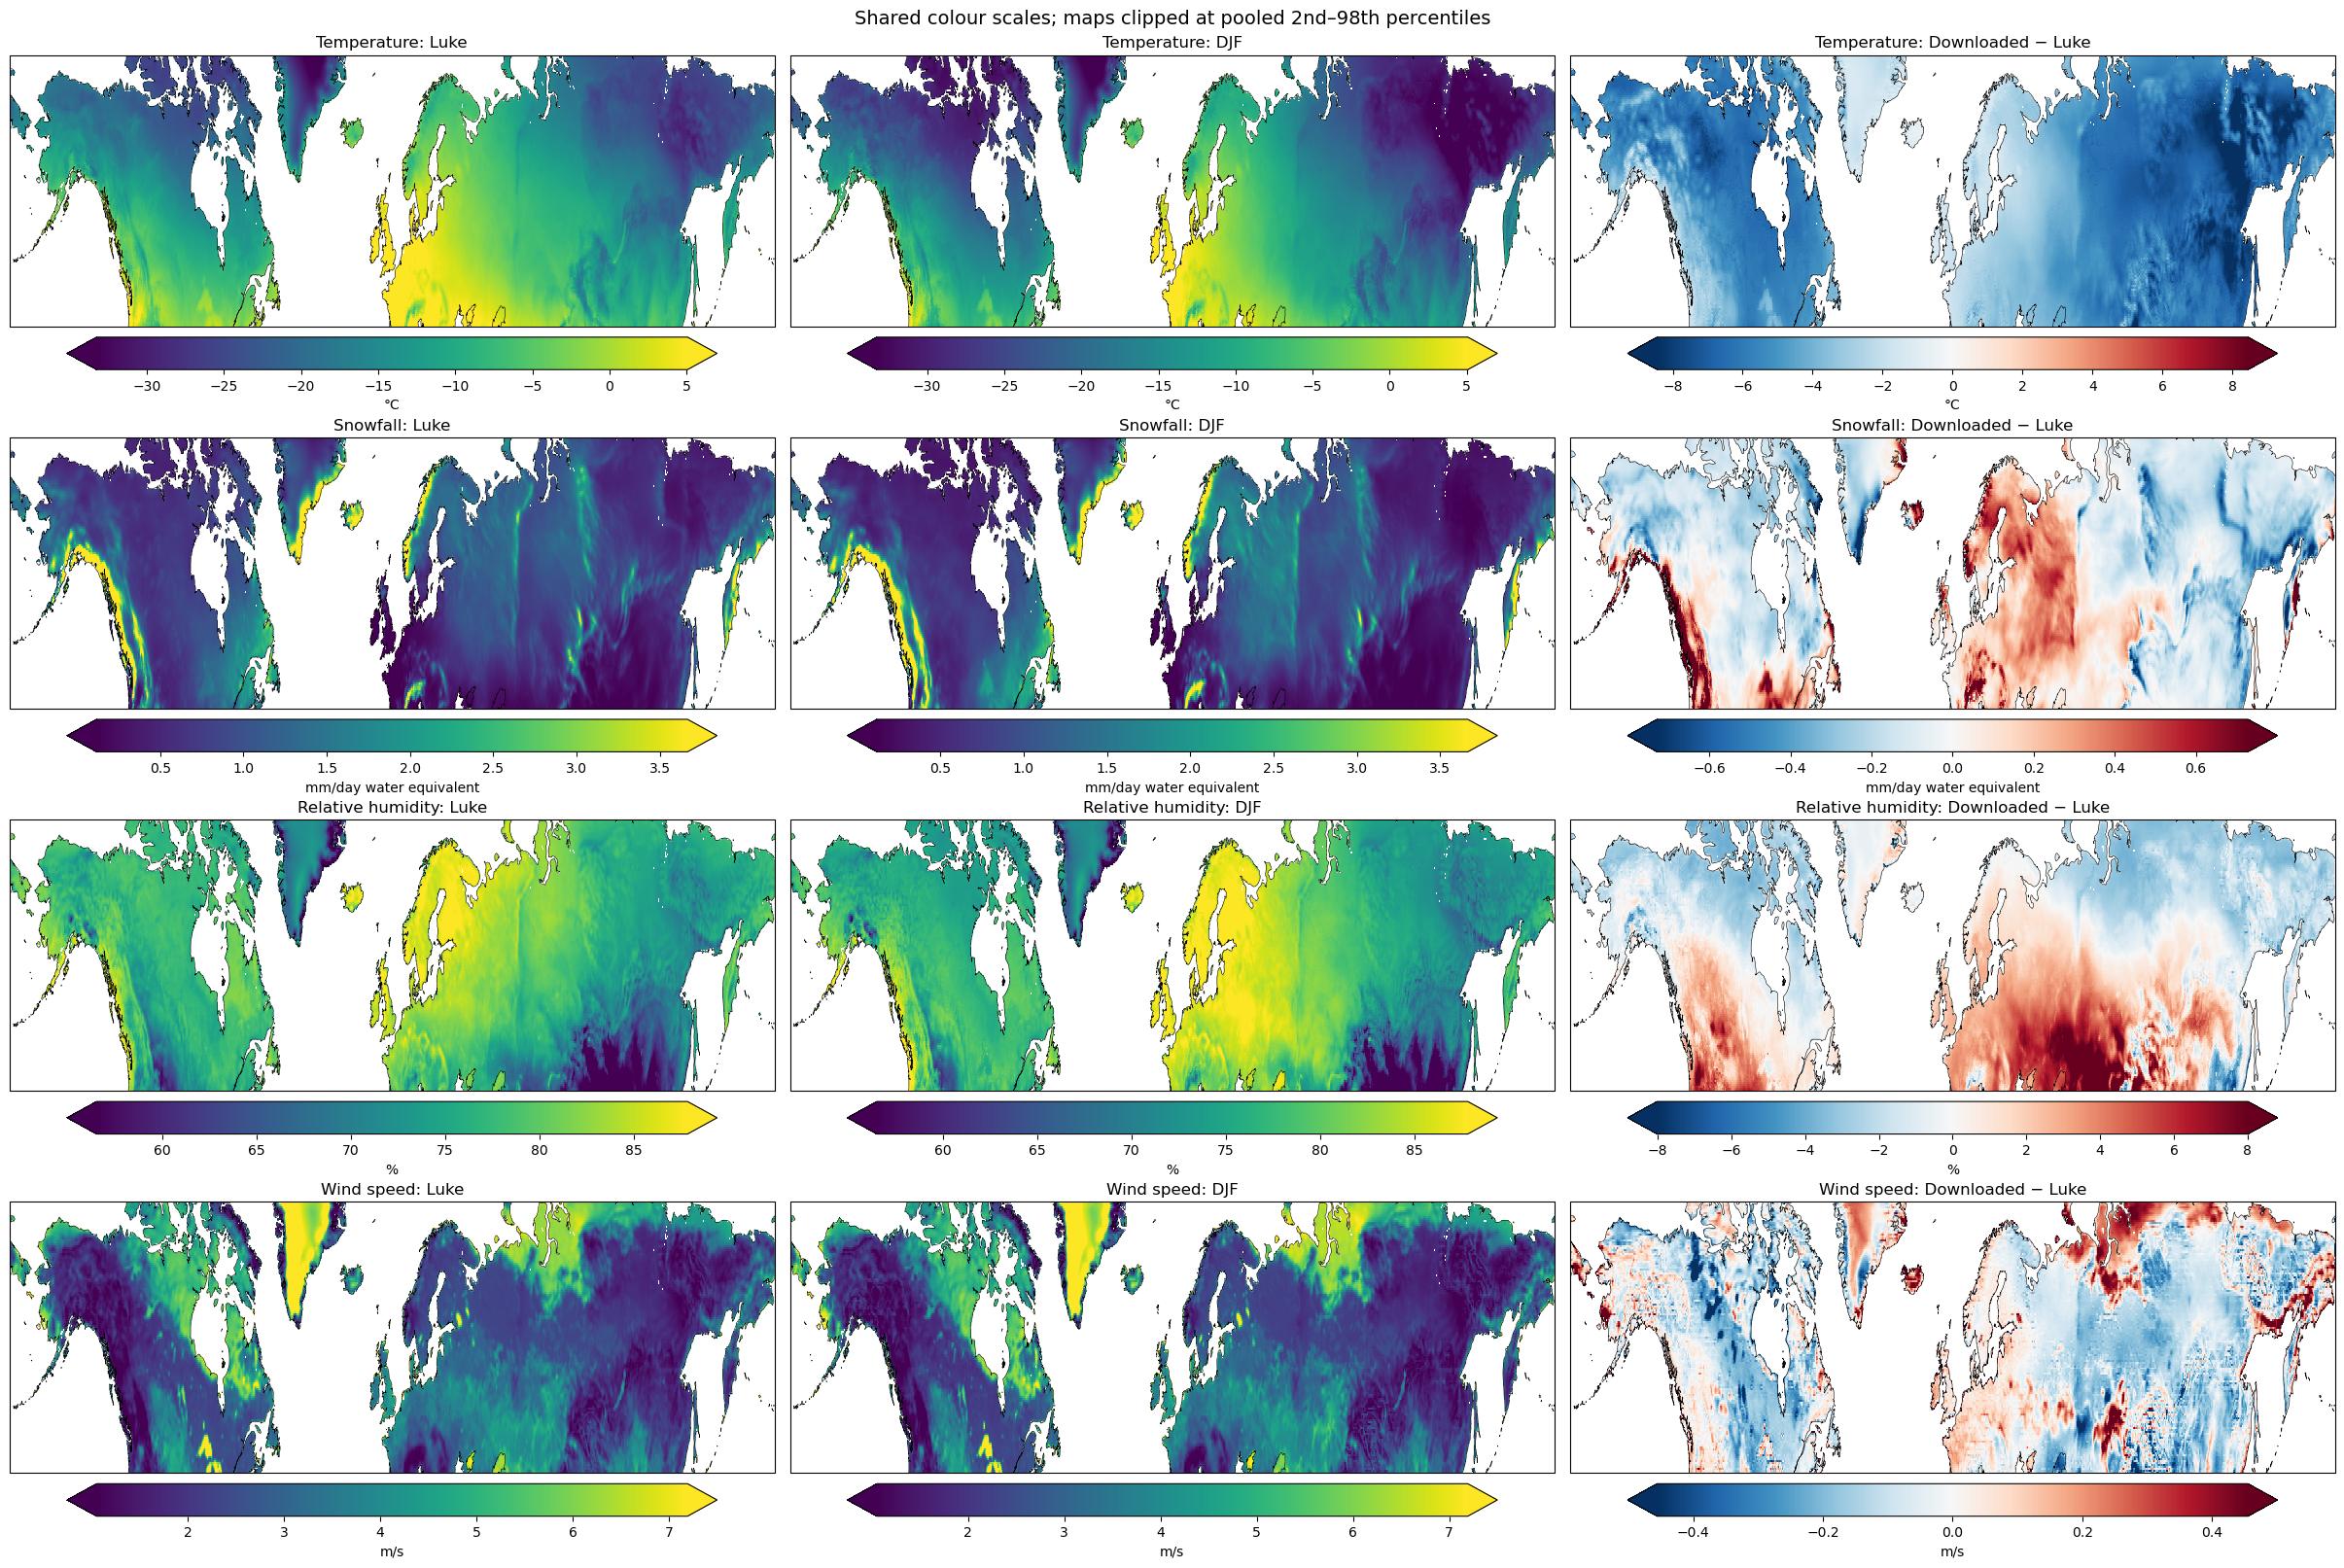

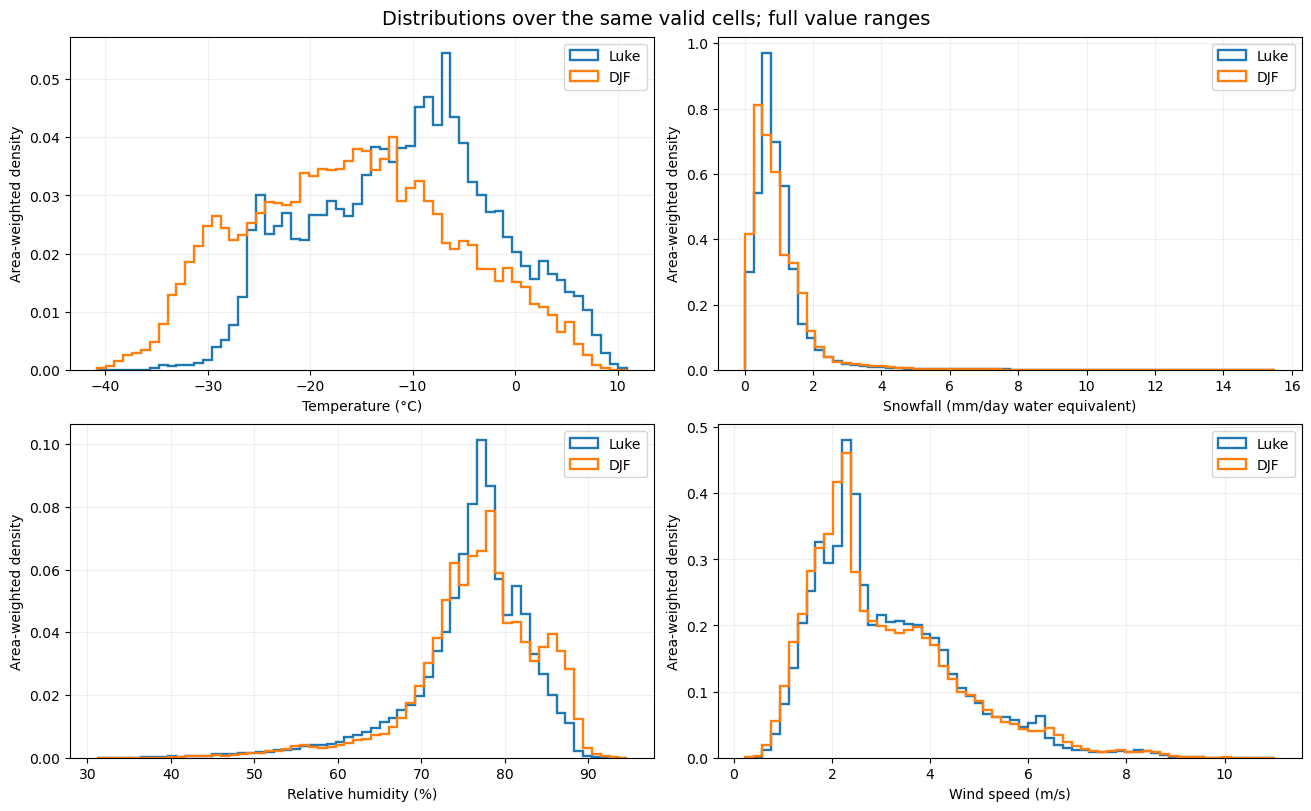

In [22]:
from pathlib import Path
import calendar
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

LUKE_NC = Path("../../scratch/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc")
SEASONAL_NC = Path("../../scratch/climate_site_selection/seasonal_climate.nc")
COMPARE_SEASON = "DJF"                  # OND, DJF or FMA.
AREA = [73, -180, 45, 180]              # North, west, south, east.
MAP_STRIDE = 2                         # Plot every second cell; distributions use all cells.


def comparison_grid(ds):
    lon = np.round((ds.longitude.values + 180) % 360 - 180, 6)
    _, keep = np.unique(lon, return_index=True)  # Remove duplicate dateline column.
    return (
        ds.isel(longitude=keep)
        .assign_coords(longitude=lon[keep])
        .sortby("latitude")
        .sortby("longitude")
    )


def season_days(season, year):
    months = {
        "OND": [(year - 1, m) for m in [10, 11, 12]],
        "DJF": [(year - 1, 12), (year, 1), (year, 2)],
        "FMA": [(year, m) for m in [2, 3, 4]],
    }
    return sum(calendar.monthrange(y, m)[1] for y, m in months[season])


fields = [
    ("air_temperature_mean", "temperature_mean", "Temperature", "°C"),
    ("snowfall_mean", "snowfall_mean", "Snowfall", "mm/day water equivalent"),
    ("relative_humidity_mean", "relative_humidity_mean", "Relative humidity", "%"),
    ("wind_speed_mean", "wind_speed_mean", "Wind speed", "m/s"),
]

comparison_maps = {}
north, west, south, east = AREA

with xr.open_dataset(LUKE_NC) as luke_raw, xr.open_dataset(SEASONAL_NC) as seasonal_raw:
    luke = comparison_grid(luke_raw)
    seasonal = comparison_grid(
        seasonal_raw.sel(season=COMPARE_SEASON, drop=True)
    )
    seasonal = seasonal.sel(
        latitude=slice(south, north), longitude=slice(west, east)
    )

    # Keep the comparison inside the area covered by both files.
    seasonal = seasonal.sel(
        latitude=slice(float(luke.latitude.min()), float(luke.latitude.max())),
        longitude=slice(float(luke.longitude.min()), float(luke.longitude.max())),
    )
    lat, lon = seasonal.latitude.values, seasonal.longitude.values

    # Crop Luke's global data before loading or interpolating.
    luke = luke.sel(
        latitude=slice(lat.min() - 0.2, lat.max() + 0.2),
        longitude=slice(lon.min() - 0.2, lon.max() + 0.2),
    )

    first, last = map(int, seasonal_raw.attrs["season_years"].split("-"))
    years = list(range(first, last + 1))
    mean_days = np.mean([season_days(COMPARE_SEASON, y) for y in years])
    complete_snow = seasonal.complete_snowfall_seasons == len(years)

    for luke_name, seasonal_name, title, unit in fields:
        a = luke[luke_name].transpose("latitude", "longitude")

        if luke_name == "air_temperature_mean":
            if a.attrs.get("units", "").lower() in ["k", "kelvin"]:
                a = a - 273.15

        # Luke's grid is shifted: interpolate its values onto the downloaded grid.
        a = a.interp(latitude=lat, longitude=lon).values
        b = seasonal[seasonal_name]

        if seasonal_name == "snowfall_mean":
            # Luke: kg/m²/day = mm/day. Downloaded: mean season total in mm.
            # Require every season-year complete so this conversion is exact.
            b = (b / mean_days).where(complete_snow)

        b = b.transpose("latitude", "longitude").values
        common = np.isfinite(a) & np.isfinite(b)
        comparison_maps[title] = (
            np.where(common, a, np.nan),
            np.where(common, b, np.nan),
            unit,
        )

    print("Luke:", luke_raw.attrs.get("winters", "years unspecified"),
          "|", luke_raw.attrs.get("periods", "periods unspecified"))
    print("Downloaded:", COMPARE_SEASON,
          "| season-years", seasonal_raw.attrs["season_years"])
    print("Snowfall: Luke's daily estimate versus downloaded ERA5 snowfall.")
    print("Differences include period, year, method and interpolation effects.")

fig, axes = plt.subplots(
    4, 3,
    figsize=(24, 16),
    subplot_kw={"projection": ccrs.PlateCarree()},
    layout="constrained",
)

for ax in axes.flat:
    ax.set_aspect("auto")  # Allow each map to fill the available height.
fig_dist, dist_axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
weights = np.broadcast_to(
    np.cos(np.deg2rad(lat))[:, None], (len(lat), len(lon))
)  # Account for smaller grid-cell areas farther north.

for row, (title, (a, b, unit)) in enumerate(comparison_maps.items()):
    valid = np.isfinite(a) & np.isfinite(b)
    if not valid.any():
        raise ValueError(f"No common valid cells for {title}")

    low, high = np.percentile(np.r_[a[valid], b[valid]], [2, 98])
    high = max(high, low + 1e-6)
    difference = b - a
    limit = max(float(np.percentile(np.abs(difference[valid]), 98)), 1e-6)

    panels = [
        (a, "Luke", low, high, "viridis"),
        (b, COMPARE_SEASON, low, high, "viridis"),
        (difference, "Downloaded − Luke", -limit, limit, "RdBu_r"),
    ]

    for ax, (values, label, vmin, vmax, cmap) in zip(axes[row], panels):
        im = ax.pcolormesh(
            lon[::MAP_STRIDE], lat[::MAP_STRIDE],
            values[::MAP_STRIDE, ::MAP_STRIDE],
            shading="auto", cmap=cmap, vmin=vmin, vmax=vmax,
            transform=ccrs.PlateCarree(),
        )
        ax.set_extent(
            [lon.min(), lon.max(), lat.min(), lat.max()],
            crs=ccrs.PlateCarree(),
        )
        ax.coastlines(linewidth=0.4)
        ax.set_title(f"{title}: {label}")
        fig.colorbar(
            im, ax=ax, orientation="horizontal", shrink=0.85,
            pad=0.03, label=unit, extend="both",
        )

    ax = dist_axes.flat[row]
    bins = np.linspace(
        min(a[valid].min(), b[valid].min()),
        max(a[valid].max(), b[valid].max()) + 1e-9, 61,
    )
    for values, label, colour in [
        (a, "Luke", "tab:blue"),
        (b, COMPARE_SEASON, "tab:orange"),
    ]:
        ax.hist(
            values[valid], bins=bins, weights=weights[valid], density=True,
            histtype="step", linewidth=1.7, label=label, color=colour,
        )
    ax.set(xlabel=f"{title} ({unit})", ylabel="Area-weighted density")
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle(
    "Shared colour scales; maps clipped at pooled 2nd–98th percentiles",
    fontsize=14,
)
fig_dist.suptitle(
    "Distributions over the same valid cells; full value ranges",
    fontsize=14,
)
plt.show()